In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Campus Road Damage Detection and Severity-Aware
# Maintenance Prioritization

## Notebook 06: Severity and Maintenance Prioritization

### Objective

To use the selected YOLOv8n-AdamW model for road
damage detection, estimate damage severity using
rule-based analysis, and generate maintenance
priority recommendations.

### Step 1: Environment Setup and Model Verification

Verify the availability of the preprocessed RDD2022
dataset, trained model, final evaluation results,
and GPU resources.

In [1]:

# ==========================================
# NOTEBOOK 06 - CELL 1
# Environment Setup and Model Verification
# ==========================================

import os
import torch
import json
import pandas as pd

from pathlib import Path

# ==========================================
# 1. Define Paths
# ==========================================

INPUT_DIR = Path("/kaggle/input")

WORK_DIR = Path("/kaggle/working")

DATASET_PATH = Path(
    "/kaggle/input/datasets/ammritkumaar/"
    "rdd2022-preprocessed-yolo"
)

PROJECT_DIR = (
    WORK_DIR /
    "Severity_Maintenance_Prioritization"
)

PROJECT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("========== ENVIRONMENT SETUP ==========")

print("Input Directory:", INPUT_DIR)

print("Working Directory:", WORK_DIR)

print("Project Directory:", PROJECT_DIR)

# ==========================================
# 2. Verify Dataset
# ==========================================

print("\n========== DATASET VERIFICATION ==========")

print("Dataset Path:", DATASET_PATH)

print("Dataset Exists:", DATASET_PATH.exists())

assert DATASET_PATH.exists(), (
    "Dataset not found. Attach the RDD2022 dataset."
)

TEST_IMAGES_DIR = DATASET_PATH / "images/test"

TEST_LABELS_DIR = DATASET_PATH / "labels/test"

test_images = sorted([

    p for p in TEST_IMAGES_DIR.iterdir()

    if p.suffix.lower() in [
        ".jpg", ".jpeg", ".png"
    ]
])

test_labels = sorted(
    TEST_LABELS_DIR.glob("*.txt")
)

print("Test Images:", len(test_images))

print("Test Labels:", len(test_labels))

assert len(test_images) == 2377

assert len(test_labels) == 2377

# ==========================================
# 3. Verify GPU
# ==========================================

print("\n========== GPU VERIFICATION ==========")

print("PyTorch Version:", torch.__version__)

print("CUDA Available:", torch.cuda.is_available())

print("GPU Count:", torch.cuda.device_count())

if torch.cuda.is_available():

    for i in range(torch.cuda.device_count()):

        gpu = torch.cuda.get_device_properties(i)

        print(f"\nGPU {i}: {gpu.name}")

        print(
            f"GPU Memory: "
            f"{gpu.total_memory / 1024**3:.2f} GB"
        )

else:

    print("WARNING: GPU not available.")

# ==========================================
# 4. Locate Final Trained Model
# ==========================================

print("\n========== FINAL MODEL SEARCH ==========")

model_files = list(
    INPUT_DIR.rglob("best_model.pt")
)

for i, path in enumerate(model_files, 1):

    print(f"\nModel {i}:")

    print("Path:", path)

    print(
        f"Size: "
        f"{path.stat().st_size / 1024**2:.2f} MB"
    )

assert len(model_files) > 0, (
    "Final model not found. Attach Notebook 05 output."
)

# Prefer the final model from Notebook 05
final_models = [

    p for p in model_files

    if "Final_Model" in p.parts

    and "Final_Test_Evaluation_Backup"
    not in p.parts
]

assert len(final_models) > 0, (
    "Notebook 05 Final_Model folder not found."
)

MODEL_PATH = final_models[0]

print("\n========== SELECTED MODEL ==========")

print("Model: YOLOv8n-AdamW")

print("Model Path:", MODEL_PATH)

print("Model Exists:", MODEL_PATH.exists())

# ==========================================
# 5. Verify Final Evaluation Summary
# ==========================================

FINAL_EVAL_DIR = MODEL_PATH.parent.parent

SUMMARY_PATH = (

    FINAL_EVAL_DIR /

    "Final_Summary" /

    "final_model_summary.json"
)

print("\n========== FINAL EVALUATION SUMMARY ==========")

print("Summary Path:", SUMMARY_PATH)

print("Summary Exists:", SUMMARY_PATH.exists())

assert SUMMARY_PATH.exists()

with open(SUMMARY_PATH, "r") as f:

    final_summary = json.load(f)

print("Model:", final_summary["Model"])

print(
    "Training Epochs:",
    final_summary["Completed Training Epochs"]
)

print(
    "Test mAP50:",
    final_summary["Test mAP50 (%)"],
    "%"
)

print(
    "Detection Accuracy:",
    final_summary["Detection Accuracy (%)"],
    "%"
)

print(
    "F1-Score:",
    final_summary["F1-Score (%)"],
    "%"
)

# ==========================================
# 6. Final Verification
# ==========================================

print("\n========== SETUP VERIFICATION ==========")

print("Dataset: READY")

print("Test Images: READY")

print("Final Model: READY")

print("Evaluation Summary: READY")

print("Project Directory: READY")

print("\n========== CELL 1 COMPLETED ==========")


========== ENVIRONMENT SETUP ==========
Input Directory: /kaggle/input
Working Directory: /kaggle/working
Project Directory: /kaggle/working/Severity_Maintenance_Prioritization

========== DATASET VERIFICATION ==========
Dataset Path: /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo
Dataset Exists: True
Test Images: 2377
Test Labels: 2377

========== GPU VERIFICATION ==========
PyTorch Version: 2.11.0+cu130
CUDA Available: True
GPU Count: 2

GPU 0: Tesla T4
GPU Memory: 14.56 GB

GPU 1: Tesla T4
GPU Memory: 14.56 GB

========== FINAL MODEL SEARCH ==========

Model 1:
Path: /kaggle/input/notebooks/ammritkumaar/05-final-test-evaluation/Final_Test_Evaluation_Backup/Final_Test_Evaluation/Final_Model/best_model.pt
Size: 30.32 MB

Model 2:
Path: /kaggle/input/notebooks/ammritkumaar/05-final-test-evaluation/Final_Test_Evaluation/Final_Model/best_model.pt
Size: 30.32 MB

========== SELECTED MODEL ==========
Model: YOLOv8n-AdamW
Model Path: /kaggle/input/notebooks/ammritkumaar/05-fi

## Step 2: Install YOLO and Load the Final Model

Install the required Ultralytics library and load
the selected YOLOv8n-AdamW model.

Verify the model's damage classes and configure
the available device for road damage detection,
severity estimation, and maintenance prioritization.

In [2]:

# ==========================================
# NOTEBOOK 06 - CELL 2
# Install YOLO and Load Final Model
# ==========================================

# Install same version used during training
!pip install -q ultralytics==8.4.211

# ==========================================
# 1. Import Libraries
# ==========================================

import torch
import ultralytics
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from ultralytics import YOLO
from pathlib import Path

# ==========================================
# 2. Verify Environment
# ==========================================

print("========== LIBRARY VERIFICATION ==========")

print("Ultralytics Version:", ultralytics.__version__)

print("PyTorch Version:", torch.__version__)

print("OpenCV Version:", cv2.__version__)

print("CUDA Available:", torch.cuda.is_available())

# ==========================================
# 3. Configure Inference Device
# ==========================================

if torch.cuda.is_available():

    DEVICE = 0

    BATCH_SIZE = 8

    print("\nUsing GPU:", torch.cuda.get_device_name(0))

else:

    DEVICE = "cpu"

    BATCH_SIZE = 4

    print("\nUsing CPU for inference")

# Inference settings
IMG_SIZE = 640

CONF_THRESHOLD = 0.25

NMS_IOU_THRESHOLD = 0.70

MAX_DETECTIONS = 300

print("\n========== INFERENCE SETTINGS ==========")

print("Device:", DEVICE)

print("Image Size:", IMG_SIZE)

print("Batch Size:", BATCH_SIZE)

print("Confidence Threshold:", CONF_THRESHOLD)

print("NMS IoU Threshold:", NMS_IOU_THRESHOLD)

print("Maximum Detections:", MAX_DETECTIONS)

# ==========================================
# 4. Load Selected Final Model
# ==========================================

assert MODEL_PATH.exists(), "Model file not found!"

model = YOLO(str(MODEL_PATH))

print("\n========== MODEL LOADED ==========")

print("Model: YOLOv8n-AdamW")

print("Model Path:", MODEL_PATH)

print("Model Task:", model.task)

print("Number of Classes:", len(model.names))

# ==========================================
# 5. Verify Road Damage Classes
# ==========================================

EXPECTED_CLASSES = {

    0: "Longitudinal Crack",

    1: "Transverse Crack",

    2: "Alligator Crack",

    3: "Pothole"
}

print("\n========== ROAD DAMAGE CLASSES ==========")

for class_id, class_name in model.names.items():

    print(f"Class {class_id}: {class_name}")

assert model.names == EXPECTED_CLASSES, (
    "Model class names do not match!"
)

# ==========================================
# 6. Create Output Directories
# ==========================================

PREDICTIONS_DIR = PROJECT_DIR / "Predictions"

REPORTS_DIR = PROJECT_DIR / "Reports"

GRAPHS_DIR = PROJECT_DIR / "Graphs"

for folder in [

    PREDICTIONS_DIR,

    REPORTS_DIR,

    GRAPHS_DIR

]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("\n========== OUTPUT DIRECTORIES ==========")

print("Predictions:", PREDICTIONS_DIR)

print("Reports:", REPORTS_DIR)

print("Graphs:", GRAPHS_DIR)

# ==========================================
# 7. Final Verification
# ==========================================

print("\n========== MODEL VERIFICATION ==========")

print("Model Loaded: YES")

print("Classes Verified: YES")

print("Inference Device: READY")

print("Output Directories: READY")

print("\n========== CELL 2 COMPLETED ==========")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
========== LIBRARY VERIFICATION ==========
Ultralytics Version: 8.4.211
PyTorch Version: 2.11.0+cu130
OpenCV Version: 4.14.0
CUDA Available: True

Using GPU: Tesla T4

========== INFERENCE SETTINGS ==========
Device: 0
Image Size: 640
Batch Size: 8
Confidence Threshold: 0.25
NMS IoU Threshold: 0.7
Maximum Detections: 300

========== MODEL LOADED ==========
Model: YOLOv8n-AdamW
Model Path: /kaggle/input/notebooks/ammritkumaar/05-final-test-evaluation/Final_Test_Evaluation/Final_Model/best_model.pt
Model Task: detect
Number of Classes: 4

========== ROAD DAMAGE CLASSES ==========
Class 0: Longitudinal Crack
Class 1: Transverse Crack
Class 2: Alligator Crack
Class 3: Pothole

========== OUTPUT DIRECTOR

## Step 3: Define Severity and Maintenance Priority Rules

Develop a rule-based severity estimation framework
using the detected road damage class and normalized
bounding box area.

Classify detected damage into Low, Medium, and High
severity levels using class-specific area thresholds.

Assign maintenance priorities as Routine, Scheduled,
Urgent, or Critical based on damage type and estimated
severity.

Note:
The proposed thresholds are heuristic and intended
for prototype demonstration. They do not represent
validated physical road damage severity standards.

In [3]:

# ==========================================
# NOTEBOOK 06 - CELL 3
# Severity and Maintenance Priority Rules
# ==========================================

import json
import pandas as pd

# ==========================================
# 1. Define Class-Specific Severity Thresholds
# ==========================================

# Area values are percentages of the image area

SEVERITY_THRESHOLDS = {

    0: {
        "name": "Longitudinal Crack",
        "medium": 2.0,
        "high": 5.0
    },

    1: {
        "name": "Transverse Crack",
        "medium": 2.0,
        "high": 5.0
    },

    2: {
        "name": "Alligator Crack",
        "medium": 3.0,
        "high": 8.0
    },

    3: {
        "name": "Pothole",
        "medium": 1.0,
        "high": 3.0
    }
}

# ==========================================
# 2. Define Maintenance Priority Rules
# ==========================================

PRIORITY_RULES = {

    0: {
        "Low": "Routine",
        "Medium": "Scheduled",
        "High": "Urgent"
    },

    1: {
        "Low": "Routine",
        "Medium": "Scheduled",
        "High": "Urgent"
    },

    2: {
        "Low": "Scheduled",
        "Medium": "Urgent",
        "High": "Critical"
    },

    3: {
        "Low": "Scheduled",
        "Medium": "Urgent",
        "High": "Critical"
    }
}

# Higher score means higher maintenance priority

PRIORITY_SCORES = {

    "Routine": 1,

    "Scheduled": 2,

    "Urgent": 3,

    "Critical": 4
}

SEVERITY_SCORES = {

    "Low": 1,

    "Medium": 2,

    "High": 3
}

# ==========================================
# 3. Define Visualization Colors
# ==========================================

# OpenCV uses BGR color format

SEVERITY_COLORS = {

    "Low": (0, 200, 0),

    "Medium": (0, 165, 255),

    "High": (0, 0, 255)
}

# ==========================================
# 4. Calculate Bounding Box Area Percentage
# ==========================================

def calculate_damage_area(
    bbox,
    image_width,
    image_height
):

    x1, y1, x2, y2 = map(float, bbox)

    # Validate image dimensions
    if image_width <= 0 or image_height <= 0:

        raise ValueError("Invalid image dimensions")

    # Clip bounding box to image boundaries
    x1 = max(0, min(x1, image_width))
    x2 = max(0, min(x2, image_width))

    y1 = max(0, min(y1, image_height))
    y2 = max(0, min(y2, image_height))

    # Bounding box dimensions
    box_width = max(0, x2 - x1)

    box_height = max(0, y2 - y1)

    # Bounding box area
    box_area = box_width * box_height

    # Total image area
    image_area = image_width * image_height

    # Relative damage area percentage
    area_percentage = (
        box_area / image_area
    ) * 100

    return area_percentage


# ==========================================
# 5. Estimate Damage Severity
# ==========================================

def estimate_severity(
    class_id,
    area_percentage
):

    class_id = int(class_id)

    thresholds = SEVERITY_THRESHOLDS[class_id]

    if area_percentage >= thresholds["high"]:

        severity = "High"

    elif area_percentage >= thresholds["medium"]:

        severity = "Medium"

    else:

        severity = "Low"

    return severity


# ==========================================
# 6. Assign Maintenance Priority
# ==========================================

def assign_maintenance_priority(
    class_id,
    severity
):

    class_id = int(class_id)

    priority = PRIORITY_RULES[class_id][severity]

    priority_score = PRIORITY_SCORES[priority]

    return priority, priority_score


# ==========================================
# 7. Complete Damage Assessment Function
# ==========================================

def assess_road_damage(
    class_id,
    confidence,
    bbox,
    image_width,
    image_height
):

    class_id = int(class_id)

    class_name = SEVERITY_THRESHOLDS[
        class_id
    ]["name"]

    # Calculate relative bounding box area
    area_percentage = calculate_damage_area(

        bbox,

        image_width,

        image_height
    )

    # Estimate severity
    severity = estimate_severity(

        class_id,

        area_percentage
    )

    # Assign maintenance priority
    priority, priority_score = (
        assign_maintenance_priority(

            class_id,

            severity
        )
    )

    return {

        "Class ID": class_id,

        "Damage Type": class_name,

        "Confidence (%)": round(
            float(confidence) * 100, 2
        ),

        "Damage Area (%)": round(
            area_percentage, 4
        ),

        "Severity": severity,

        "Severity Score": SEVERITY_SCORES[
            severity
        ],

        "Maintenance Priority": priority,

        "Priority Score": priority_score
    }


# ==========================================
# 8. Display Severity Thresholds
# ==========================================

threshold_rows = []

for class_id, rule in SEVERITY_THRESHOLDS.items():

    threshold_rows.append({

        "Class ID": class_id,

        "Damage Type": rule["name"],

        "Low Severity": (
            f"< {rule['medium']}%"
        ),

        "Medium Severity": (
            f"{rule['medium']}% to "
            f"< {rule['high']}%"
        ),

        "High Severity": (
            f">= {rule['high']}%"
        )
    })

threshold_df = pd.DataFrame(threshold_rows)

print("========== SEVERITY THRESHOLDS ==========")

display(threshold_df)

# ==========================================
# 9. Display Maintenance Priority Rules
# ==========================================

priority_rows = []

for class_id, rules in PRIORITY_RULES.items():

    priority_rows.append({

        "Damage Type": SEVERITY_THRESHOLDS[
            class_id
        ]["name"],

        "Low Severity": rules["Low"],

        "Medium Severity": rules["Medium"],

        "High Severity": rules["High"]
    })

priority_df = pd.DataFrame(priority_rows)

print("\n========== MAINTENANCE PRIORITY RULES ==========")

display(priority_df)

# ==========================================
# 10. Test All Severity and Priority Rules
# ==========================================

# Synthetic examples for checking rule logic
# These are NOT actual model predictions

demo_results = []

for class_id, thresholds in SEVERITY_THRESHOLDS.items():

    test_areas = [

        thresholds["medium"] / 2,

        thresholds["medium"],

        thresholds["high"]
    ]

    expected_severities = [

        "Low",

        "Medium",

        "High"
    ]

    for area, expected in zip(
        test_areas,
        expected_severities
    ):

        severity = estimate_severity(

            class_id,

            area
        )

        priority, score = (
            assign_maintenance_priority(

                class_id,

                severity
            )
        )

        assert severity == expected

        demo_results.append({

            "Damage Type": thresholds["name"],

            "Area (%)": area,

            "Expected Severity": expected,

            "Predicted Severity": severity,

            "Maintenance Priority": priority,

            "Priority Score": score,

            "Test Status": "PASS"
        })

demo_df = pd.DataFrame(demo_results)

print("\n========== RULE VERIFICATION ==========")

display(demo_df)

# ==========================================
# 11. Test Complete Assessment Function
# ==========================================

# Example:
# Image = 640 x 640
# Pothole bounding box = 200 x 100 pixels

sample_assessment = assess_road_damage(

    class_id=3,

    confidence=0.85,

    bbox=[100, 100, 300, 200],

    image_width=640,

    image_height=640
)

print("\n========== SAMPLE DAMAGE ASSESSMENT ==========")

display(
    pd.DataFrame([sample_assessment])
)

assert sample_assessment["Severity"] == "High"

assert (
    sample_assessment["Maintenance Priority"]
    == "Critical"
)

# ==========================================
# 12. Save Rules and Configuration
# ==========================================

threshold_df.to_csv(

    REPORTS_DIR / "severity_thresholds.csv",

    index=False
)

priority_df.to_csv(

    REPORTS_DIR / "maintenance_priority_rules.csv",

    index=False
)

demo_df.to_csv(

    REPORTS_DIR / "rule_verification.csv",

    index=False
)

rules_config = {

    "method": "Rule-based severity estimation",

    "area_measurement": (
        "Bounding box area percentage "
        "relative to image area"
    ),

    "severity_thresholds": SEVERITY_THRESHOLDS,

    "priority_rules": PRIORITY_RULES,

    "priority_scores": PRIORITY_SCORES,

    "severity_scores": SEVERITY_SCORES,

    "confidence_threshold": CONF_THRESHOLD,

    "limitations": [

        "Heuristic thresholds for prototype use",

        "No ground-truth severity labels",

        "Bounding box area is not physical damage area",

        "Damage depth is not measured",

        "Confidence is not a severity measurement",

        "Maintenance recommendations require field validation"
    ]
}

with open(

    REPORTS_DIR / "severity_priority_config.json",

    "w"

) as file:

    json.dump(

        rules_config,

        file,

        indent=4
    )

# ==========================================
# 13. Final Verification
# ==========================================

print("\n========== CONFIGURATION SAVED ==========")

print("severity_thresholds.csv")

print("maintenance_priority_rules.csv")

print("rule_verification.csv")

print("severity_priority_config.json")

print("\nAll 12 severity rule tests: PASSED")

print("Complete assessment test: PASSED")

print("\n========== CELL 3 COMPLETED ==========")


========== SEVERITY THRESHOLDS ==========


,Class ID,Damage Type,Low Severity,Medium Severity,High Severity
0,0,Longitudinal Crack,< 2.0%,2.0% to < 5.0%,>= 5.0%
1,1,Transverse Crack,< 2.0%,2.0% to < 5.0%,>= 5.0%
2,2,Alligator Crack,< 3.0%,3.0% to < 8.0%,>= 8.0%
3,3,Pothole,< 1.0%,1.0% to < 3.0%,>= 3.0%



========== MAINTENANCE PRIORITY RULES ==========


,Damage Type,Low Severity,Medium Severity,High Severity
0,Longitudinal Crack,Routine,Scheduled,Urgent
1,Transverse Crack,Routine,Scheduled,Urgent
2,Alligator Crack,Scheduled,Urgent,Critical
3,Pothole,Scheduled,Urgent,Critical



========== RULE VERIFICATION ==========


,Damage Type,Area (%),Expected Severity,Predicted Severity,Maintenance Priority,Priority Score,Test Status
0,Longitudinal Crack,1.0,Low,Low,Routine,1,PASS
1,Longitudinal Crack,2.0,Medium,Medium,Scheduled,2,PASS
2,Longitudinal Crack,5.0,High,High,Urgent,3,PASS
3,Transverse Crack,1.0,Low,Low,Routine,1,PASS
4,Transverse Crack,2.0,Medium,Medium,Scheduled,2,PASS
5,Transverse Crack,5.0,High,High,Urgent,3,PASS
6,Alligator Crack,1.5,Low,Low,Scheduled,2,PASS
7,Alligator Crack,3.0,Medium,Medium,Urgent,3,PASS
8,Alligator Crack,8.0,High,High,Critical,4,PASS
9,Pothole,0.5,Low,Low,Scheduled,2,PASS



========== SAMPLE DAMAGE ASSESSMENT ==========


,Class ID,Damage Type,Confidence (%),Damage Area (%),Severity,Severity Score,Maintenance Priority,Priority Score
0,3,Pothole,85.0,4.8828,High,3,Critical,4



========== CONFIGURATION SAVED ==========
severity_thresholds.csv
maintenance_priority_rules.csv
rule_verification.csv
severity_priority_config.json

All 12 severity rule tests: PASSED
Complete assessment test: PASSED

========== CELL 3 COMPLETED ==========


## Step 4: Road Damage Detection and Severity Estimation

Perform road damage detection on the complete
independent test dataset using the selected
YOLOv8n-AdamW model.

For each detected damage instance, calculate the
relative bounding box area, estimate its severity,
and assign a maintenance priority using the
predefined rule-based framework.

Save individual damage assessments and image-level
summaries for visualization and maintenance ranking.

In [5]:

# ==========================================
# NOTEBOOK 06 - CELL 4
# Road Damage Detection and Severity Estimation
# Corrected - Same Settings as Notebook 05
# ==========================================

import time
import torch
import numpy as np
import pandas as pd
import json
import gc

from pathlib import Path
from tqdm.auto import tqdm
from ultralytics import YOLO

# ==========================================
# 1. Configure Inference
# ==========================================

PRED_BATCH_SIZE = 8
PRED_DEVICE = 1
USE_FP16 = True

assert torch.cuda.is_available(), "GPU not available!"
assert torch.cuda.device_count() >= 2, "GPU 1 not available!"

# Clear previous model and GPU memory
if "model" in globals():
    del model

if "result" in globals():
    del result

gc.collect()
torch.cuda.empty_cache()

# Load fresh model
model = YOLO(str(MODEL_PATH))

print("========== INFERENCE CONFIGURATION ==========")

print("Model: YOLOv8n-AdamW")
print("Total Test Images:", len(test_images))
print("Image Size:", IMG_SIZE)
print("Batch Size:", PRED_BATCH_SIZE)
print("Device:", PRED_DEVICE)
print("GPU:", torch.cuda.get_device_name(PRED_DEVICE))
print("Precision Mode: FP16")
print("Confidence Threshold:", CONF_THRESHOLD)
print("NMS IoU Threshold:", NMS_IOU_THRESHOLD)
print("Maximum Detections:", MAX_DETECTIONS)

# ==========================================
# 2. Initialize Result Storage
# ==========================================

damage_records = []
image_records = []

processed_images = 0
total_detections = 0

start_time = time.time()

# ==========================================
# 3. Run Predictions in Small Batches
# ==========================================

def generate_predictions():

    for start in range(
        0, len(test_images), PRED_BATCH_SIZE
    ):

        batch_paths = [
            str(p)
            for p in test_images[
                start:start + PRED_BATCH_SIZE
            ]
        ]

        batch_results = model.predict(
            source=batch_paths,
            imgsz=IMG_SIZE,
            conf=CONF_THRESHOLD,
            iou=NMS_IOU_THRESHOLD,
            max_det=MAX_DETECTIONS,
            device=PRED_DEVICE,
            batch=PRED_BATCH_SIZE,
            half=USE_FP16,
            stream=True,
            verbose=False,
            save=False
        )

        for result in batch_results:

            yield result

        del batch_results


# ==========================================
# 4. Process Every Road Image
# ==========================================

print("\n========== ROAD DAMAGE DETECTION ==========")

for result in tqdm(
    generate_predictions(),
    total=len(test_images),
    desc="Detecting and Assessing Damage"
):

    image_path = Path(result.path)
    image_name = image_path.name

    # Original image dimensions
    image_height, image_width = result.orig_shape

    # Get predicted bounding boxes
    boxes = result.boxes.xyxy.cpu().numpy()

    classes = (
        result.boxes.cls.cpu().numpy().astype(int)
    )

    confidences = (
        result.boxes.conf.cpu().numpy()
    )

    image_damages = []

    # ======================================
    # 5. Assess Every Detected Damage
    # ======================================

    for detection_id, (
        bbox, class_id, confidence
    ) in enumerate(
        zip(boxes, classes, confidences),
        start=1
    ):

        assessment = assess_road_damage(
            class_id=class_id,
            confidence=confidence,
            bbox=bbox,
            image_width=image_width,
            image_height=image_height
        )

        x1, y1, x2, y2 = map(float, bbox)

        damage_record = {

            "Image Name": image_name,

            "Image Path": str(image_path),

            "Detection ID": detection_id,

            "Image Width": image_width,

            "Image Height": image_height,

            "X1": round(x1, 2),

            "Y1": round(y1, 2),

            "X2": round(x2, 2),

            "Y2": round(y2, 2),

            **assessment
        }

        damage_records.append(damage_record)

        image_damages.append(damage_record)

        total_detections += 1

    # ======================================
    # 6. Generate Image-Level Summary
    # ======================================

    if len(image_damages) > 0:

        # Highest-priority detected damage
        highest_damage = max(
            image_damages,
            key=lambda d: (
                d["Priority Score"],
                d["Severity Score"],
                d["Damage Area (%)"]
            )
        )

        highest_priority = highest_damage[
            "Maintenance Priority"
        ]

        highest_priority_score = highest_damage[
            "Priority Score"
        ]

        highest_severity = max(
            image_damages,
            key=lambda d: d["Severity Score"]
        )["Severity"]

        dominant_damage = highest_damage[
            "Damage Type"
        ]

        average_confidence = np.mean([
            d["Confidence (%)"]
            for d in image_damages
        ])

        low_count = sum(
            d["Severity"] == "Low"
            for d in image_damages
        )

        medium_count = sum(
            d["Severity"] == "Medium"
            for d in image_damages
        )

        high_count = sum(
            d["Severity"] == "High"
            for d in image_damages
        )

        critical_count = sum(
            d["Maintenance Priority"] == "Critical"
            for d in image_damages
        )

        detection_status = "Damage Detected"

    else:

        highest_priority = "Not Assessed"

        highest_priority_score = 0

        highest_severity = "Not Assessed"

        dominant_damage = "None Detected"

        average_confidence = None

        low_count = 0

        medium_count = 0

        high_count = 0

        critical_count = 0

        detection_status = "No Damage Detected"

    image_record = {

        "Image Name": image_name,

        "Image Path": str(image_path),

        "Detection Status": detection_status,

        "Total Detections": len(image_damages),

        "Low Severity Count": low_count,

        "Medium Severity Count": medium_count,

        "High Severity Count": high_count,

        "Critical Damage Count": critical_count,

        "Highest Severity": highest_severity,

        "Highest Priority": highest_priority,

        "Priority Score": highest_priority_score,

        "Highest Priority Damage Type": dominant_damage,

        "Average Confidence (%)": (
            round(float(average_confidence), 2)
            if average_confidence is not None
            else None
        )
    }

    image_records.append(image_record)

    processed_images += 1

# ==========================================
# 7. Create Final DataFrames
# ==========================================

damage_df = pd.DataFrame(damage_records)

image_summary_df = pd.DataFrame(image_records)

inference_time = time.time() - start_time

assert processed_images == len(test_images)

assert len(image_summary_df) == len(test_images)

assert len(damage_df) == total_detections

assert total_detections > 0

assert image_summary_df[
    "Image Name"
].nunique() == len(test_images)

# ==========================================
# 8. Display Processing Summary
# ==========================================

print("\n========== DETECTION COMPLETED ==========")

print("Processed Images:", processed_images)

print("Total Damage Detections:", total_detections)

images_with_damage = int(
    (
        image_summary_df["Total Detections"] > 0
    ).sum()
)

images_without_detection = int(
    (
        image_summary_df["Total Detections"] == 0
    ).sum()
)

print(
    "Images with Damage Detected:",
    images_with_damage
)

print(
    "Images with No Damage Detected:",
    images_without_detection
)

print(
    f"Total Processing Time: "
    f"{inference_time / 60:.2f} minutes"
)

print(
    f"Average Processing Time: "
    f"{inference_time / processed_images:.4f} sec/image"
)

# ==========================================
# 9. Damage Type Distribution
# ==========================================

damage_distribution = (
    damage_df["Damage Type"]
    .value_counts()
    .reindex(
        list(EXPECTED_CLASSES.values()),
        fill_value=0
    )
    .rename_axis("Damage Type")
    .reset_index(name="Detections")
)

print("\n========== DAMAGE TYPE DISTRIBUTION ==========")

display(damage_distribution)

# ==========================================
# 10. Severity Distribution
# ==========================================

severity_distribution = (
    damage_df["Severity"]
    .value_counts()
    .reindex(
        ["Low", "Medium", "High"],
        fill_value=0
    )
    .rename_axis("Severity")
    .reset_index(name="Detections")
)

print("\n========== SEVERITY DISTRIBUTION ==========")

display(severity_distribution)

# ==========================================
# 11. Maintenance Priority Distribution
# ==========================================

priority_distribution = (
    damage_df["Maintenance Priority"]
    .value_counts()
    .reindex(
        [
            "Routine",
            "Scheduled",
            "Urgent",
            "Critical"
        ],
        fill_value=0
    )
    .rename_axis("Maintenance Priority")
    .reset_index(name="Detections")
)

print("\n========== MAINTENANCE PRIORITY DISTRIBUTION ==========")

display(priority_distribution)

# ==========================================
# 12. Compare with Notebook 05 Predictions
# ==========================================

NOTEBOOK_05_PREDICTIONS = 3289

prediction_count_match = (
    total_detections == NOTEBOOK_05_PREDICTIONS
)

print("\n========== NOTEBOOK 05 CONSISTENCY CHECK ==========")

print(
    "Notebook 05 Predictions:",
    NOTEBOOK_05_PREDICTIONS
)

print(
    "Notebook 06 Predictions:",
    total_detections
)

print(
    "Prediction Count Difference:",
    total_detections - NOTEBOOK_05_PREDICTIONS
)

print(
    "Prediction Count Match:",
    prediction_count_match
)

if prediction_count_match:

    print("SUCCESS: Prediction counts match!")

else:

    print(
        "NOTE: Prediction counts differ slightly. "
        "Review inference settings if required."
    )

# Notebook 05 class-wise prediction counts
# Calculated from TP + FP

notebook05_class_counts = {

    "Longitudinal Crack": 1583,

    "Transverse Crack": 712,

    "Alligator Crack": 718,

    "Pothole": 276
}

consistency_rows = []

for damage_type in EXPECTED_CLASSES.values():

    previous_count = notebook05_class_counts[
        damage_type
    ]

    current_count = int(
        (
            damage_df["Damage Type"] == damage_type
        ).sum()
    )

    consistency_rows.append({

        "Damage Type": damage_type,

        "Notebook 05": previous_count,

        "Notebook 06": current_count,

        "Difference": current_count - previous_count,

        "Match": previous_count == current_count
    })

consistency_df = pd.DataFrame(consistency_rows)

display(consistency_df)

# ==========================================
# 13. Display Sample Assessments
# ==========================================

print("\n========== SAMPLE DAMAGE ASSESSMENTS ==========")

display(
    damage_df[[
        "Image Name",
        "Damage Type",
        "Confidence (%)",
        "Damage Area (%)",
        "Severity",
        "Maintenance Priority",
        "Priority Score"
    ]].head(10)
)

print("\n========== SAMPLE IMAGE SUMMARIES ==========")

display(
    image_summary_df[[
        "Image Name",
        "Total Detections",
        "Highest Severity",
        "Highest Priority",
        "Priority Score"
    ]].head(10)
)

# ==========================================
# 14. Save All Assessment Reports
# ==========================================

damage_df.to_csv(
    REPORTS_DIR / "damage_assessment_report.csv",
    index=False
)

image_summary_df.to_csv(
    REPORTS_DIR / "image_level_summary.csv",
    index=False
)

damage_distribution.to_csv(
    REPORTS_DIR / "damage_type_distribution.csv",
    index=False
)

severity_distribution.to_csv(
    REPORTS_DIR / "severity_distribution.csv",
    index=False
)

priority_distribution.to_csv(
    REPORTS_DIR / "priority_distribution.csv",
    index=False
)

consistency_df.to_csv(
    REPORTS_DIR / "prediction_consistency_check.csv",
    index=False
)

# ==========================================
# 15. Save Processing Statistics
# ==========================================

processing_summary = {

    "model": "YOLOv8n-AdamW",

    "completed_training_epochs": 16,

    "processed_images": int(processed_images),

    "total_detections": int(total_detections),

    "images_with_damage_detected": images_with_damage,

    "images_without_detection": images_without_detection,

    "confidence_threshold": CONF_THRESHOLD,

    "nms_iou_threshold": NMS_IOU_THRESHOLD,

    "max_detections": MAX_DETECTIONS,

    "image_size": IMG_SIZE,

    "batch_size": PRED_BATCH_SIZE,

    "device": str(PRED_DEVICE),

    "gpu_name": torch.cuda.get_device_name(
        PRED_DEVICE
    ),

    "precision_mode": "FP16",

    "notebook05_predictions": NOTEBOOK_05_PREDICTIONS,

    "prediction_count_match": bool(
        prediction_count_match
    ),

    "prediction_count_difference": int(
        total_detections - NOTEBOOK_05_PREDICTIONS
    ),

    "processing_time_seconds": round(
        inference_time, 2
    ),

    "severity_method": (
        "Class-specific bounding box area rules"
    ),

    "severity_validation": (
        "Heuristic rules only; no ground-truth "
        "severity labels available"
    ),

    "no_detection_interpretation": (
        "No detection does not establish that "
        "the road is damage-free"
    )
}

with open(
    REPORTS_DIR / "processing_summary.json",
    "w"
) as file:

    json.dump(
        processing_summary,
        file,
        indent=4
    )

# ==========================================
# 16. Verify Saved Reports
# ==========================================

required_reports = [

    "damage_assessment_report.csv",

    "image_level_summary.csv",

    "damage_type_distribution.csv",

    "severity_distribution.csv",

    "priority_distribution.csv",

    "prediction_consistency_check.csv",

    "processing_summary.json"
]

print("\n========== REPORT VERIFICATION ==========")

for filename in required_reports:

    file_path = REPORTS_DIR / filename

    assert file_path.exists()

    print("Verified:", filename)

print("\nAll assessment reports saved successfully!")

print("\n========== CELL 4 COMPLETED ==========")


========== INFERENCE CONFIGURATION ==========
Model: YOLOv8n-AdamW
Total Test Images: 2377
Image Size: 640
Batch Size: 8
Device: 1
GPU: Tesla T4
Precision Mode: FP16
Confidence Threshold: 0.25
NMS IoU Threshold: 0.7
Maximum Detections: 300

========== ROAD DAMAGE DETECTION ==========


Detecting and Assessing Damage:   0%|          | 0/2377 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

,Damage Type,Detections
0,Longitudinal Crack,1583
1,Transverse Crack,712
2,Alligator Crack,718
3,Pothole,276



========== SEVERITY DISTRIBUTION ==========


,Severity,Detections
0,Low,1374
1,Medium,795
2,High,1120


... (5 outputs left out)

,Image Name,Damage Type,Confidence (%),Damage Area (%),Severity,Maintenance Priority,Priority Score
0,China_Drone_000010.jpg,Longitudinal Crack,65.33,1.5400,Low,Routine,1
1,China_Drone_000010.jpg,Longitudinal Crack,45.90,2.8057,Medium,Scheduled,2
2,China_Drone_000010.jpg,Longitudinal Crack,25.83,0.9646,Low,Routine,1
3,China_Drone_000022.jpg,Transverse Crack,45.90,5.0149,High,Urgent,3
4,China_Drone_000022.jpg,Longitudinal Crack,37.84,3.9734,Medium,Scheduled,2
5,China_Drone_000022.jpg,Longitudinal Crack,33.45,2.5428,Medium,Scheduled,2
6,China_Drone_000022.jpg,Longitudinal Crack,27.51,0.9359,Low,Routine,1
7,China_Drone_000055.jpg,Longitudinal Crack,32.93,8.3856,High,Urgent,3
8,China_Drone_000057.jpg,Pothole,45.14,0.8844,Low,Scheduled,2
9,China_Drone_000057.jpg,Pothole,25.98,0.5278,Low,Scheduled,2



========== SAMPLE IMAGE SUMMARIES ==========


,Image Name,Total Detections,Highest Severity,Highest Priority,Priority Score
0,China_Drone_000010.jpg,3,Medium,Scheduled,2
1,China_Drone_000022.jpg,4,High,Urgent,3
2,China_Drone_000055.jpg,1,High,Urgent,3
3,China_Drone_000057.jpg,2,Low,Scheduled,2
4,China_Drone_000079.jpg,1,Low,Routine,1
5,China_Drone_000094.jpg,0,Not Assessed,Not Assessed,0
6,China_Drone_000098.jpg,2,Medium,Scheduled,2
7,China_Drone_000112.jpg,1,Low,Routine,1
8,China_Drone_000113.jpg,2,Medium,Scheduled,2
9,China_Drone_000158.jpg,3,High,Urgent,3



========== REPORT VERIFICATION ==========
Verified: damage_assessment_report.csv
Verified: image_level_summary.csv
Verified: damage_type_distribution.csv
Verified: severity_distribution.csv
Verified: priority_distribution.csv
Verified: prediction_consistency_check.csv
Verified: processing_summary.json

All assessment reports saved successfully!

========== CELL 4 COMPLETED ==========


## Step 5: Visualize Road Damage and Maintenance Priority

Visualize representative road damage predictions using
the selected YOLOv8n-AdamW model's detection results.

For each selected road image, display:

- Detected road damage type
- Bounding box and confidence score
- Estimated damage severity
- Assigned maintenance priority

Use color-coded bounding boxes to represent severity:

- Green: Low Severity
- Orange: Medium Severity
- Red: High Severity

Generate representative visualizations for all four
damage classes and three severity levels.

Additionally, visualize the four maintenance priority
categories: Routine, Scheduled, Urgent, and Critical.

Save annotated images, visualization grids, and sample
reports for project documentation and demonstration.

Note: Severity and maintenance priorities are estimated
using the proposed heuristic rules and are not validated
physical road damage measurements.

========== VISUALIZATION SETUP ==========
Output Directory: /kaggle/working/Severity_Maintenance_Prioritization/Predictions/Annotated_Images
Available Damage Records: 3289
Available Image Records: 2377
Updated FP16 Predictions: VERIFIED

========== SELECTED VISUALIZATION SAMPLES ==========
Total Selected Samples: 12


,Image Name,Damage Type,Severity,Maintenance Priority,Confidence (%),Damage Area (%)
0,Norway_002451.jpg,Longitudinal Crack,Low,Routine,83.54,1.2848
1,United_States_002902.jpg,Longitudinal Crack,Medium,Scheduled,86.52,3.1068
2,United_States_003632.jpg,Longitudinal Crack,High,Urgent,86.13,5.5209
3,China_MotorBike_000469.jpg,Transverse Crack,Low,Routine,66.89,1.9336
4,China_MotorBike_001277.jpg,Transverse Crack,Medium,Scheduled,65.33,4.7289
5,China_MotorBike_000928.jpg,Transverse Crack,High,Urgent,67.04,30.6011
6,Japan_003659.jpg,Alligator Crack,Low,Scheduled,73.88,2.1891
7,Japan_008622.jpg,Alligator Crack,Medium,Urgent,69.53,7.6479
8,China_MotorBike_001650.jpg,Alligator Crack,High,Critical,90.82,74.1406
9,India_001932.jpg,Pothole,Low,Scheduled,78.66,0.6204



========== SAVING ANNOTATED IMAGES ==========
Saved: 01_Longitudinal_Crack_Low_Norway_002451.jpg
Saved: 02_Longitudinal_Crack_Medium_United_States_002902.jpg
Saved: 03_Longitudinal_Crack_High_United_States_003632.jpg
Saved: 04_Transverse_Crack_Low_China_MotorBike_000469.jpg
Saved: 05_Transverse_Crack_Medium_China_MotorBike_001277.jpg
Saved: 06_Transverse_Crack_High_China_MotorBike_000928.jpg
Saved: 07_Alligator_Crack_Low_Japan_003659.jpg
Saved: 08_Alligator_Crack_Medium_Japan_008622.jpg
Saved: 09_Alligator_Crack_High_China_MotorBike_001650.jpg
Saved: 10_Pothole_Low_India_001932.jpg
Saved: 11_Pothole_Medium_India_004070.jpg
Saved: 12_Pothole_High_China_MotorBike_001562.jpg


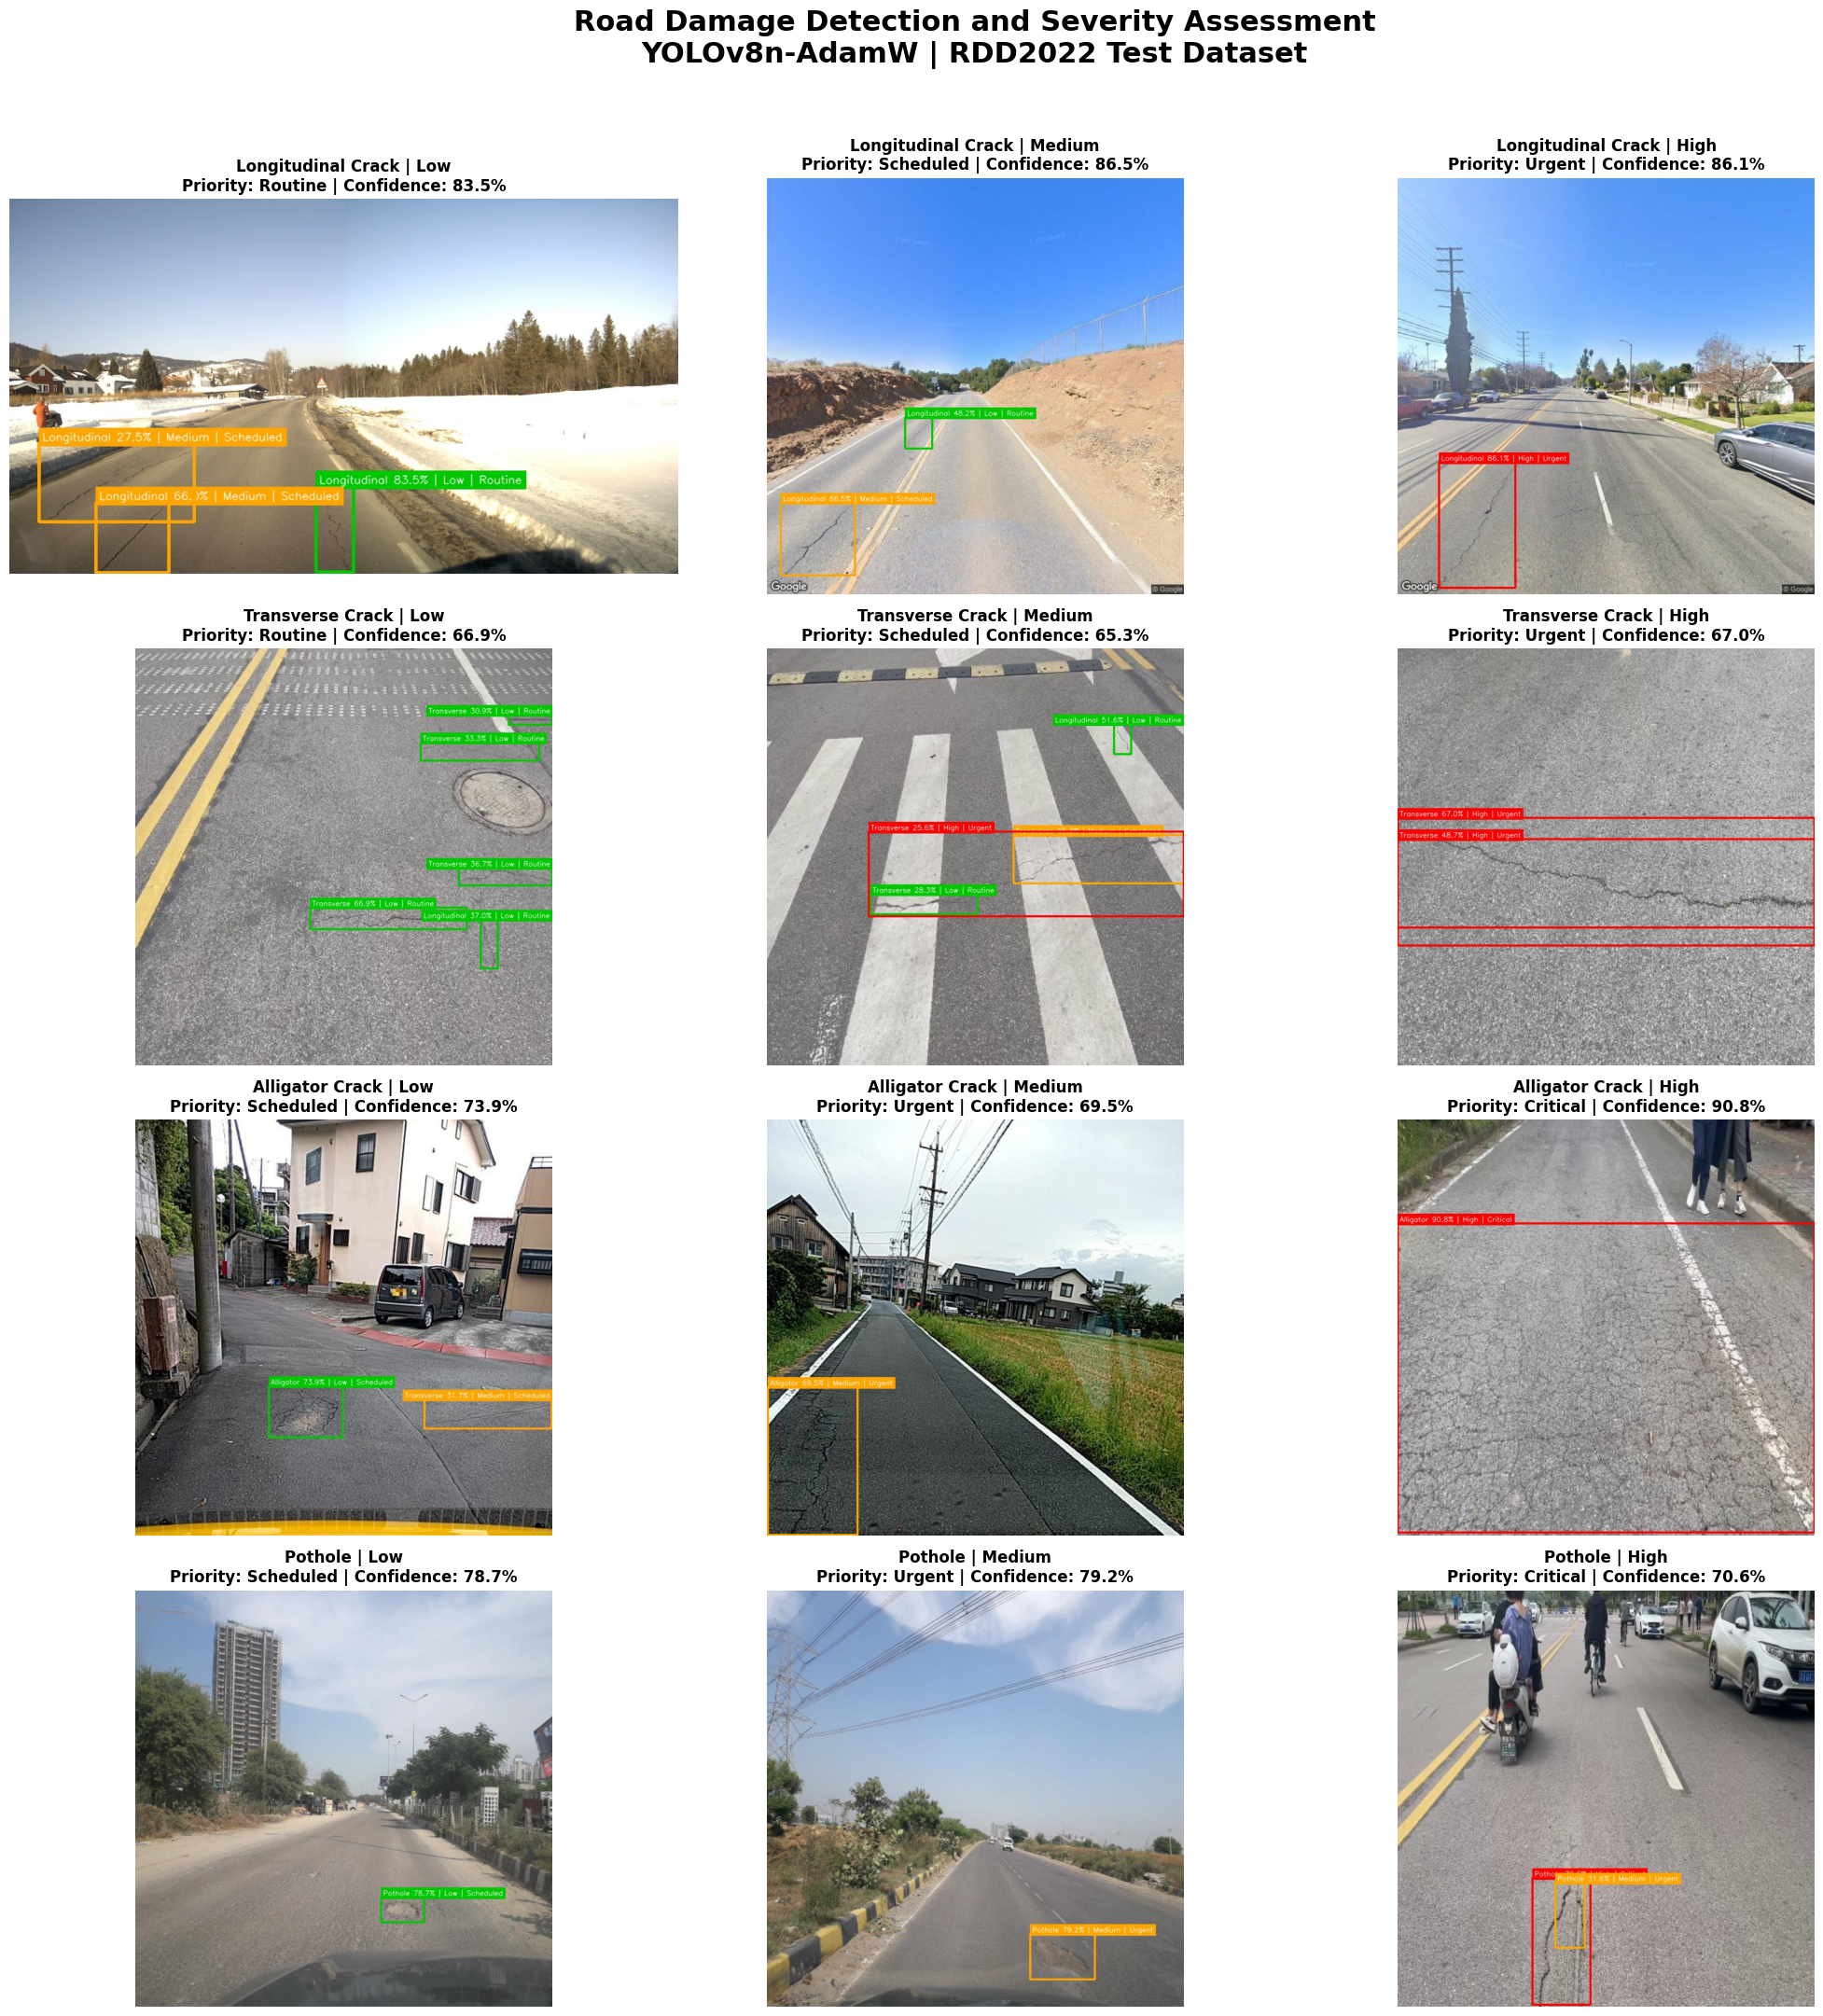

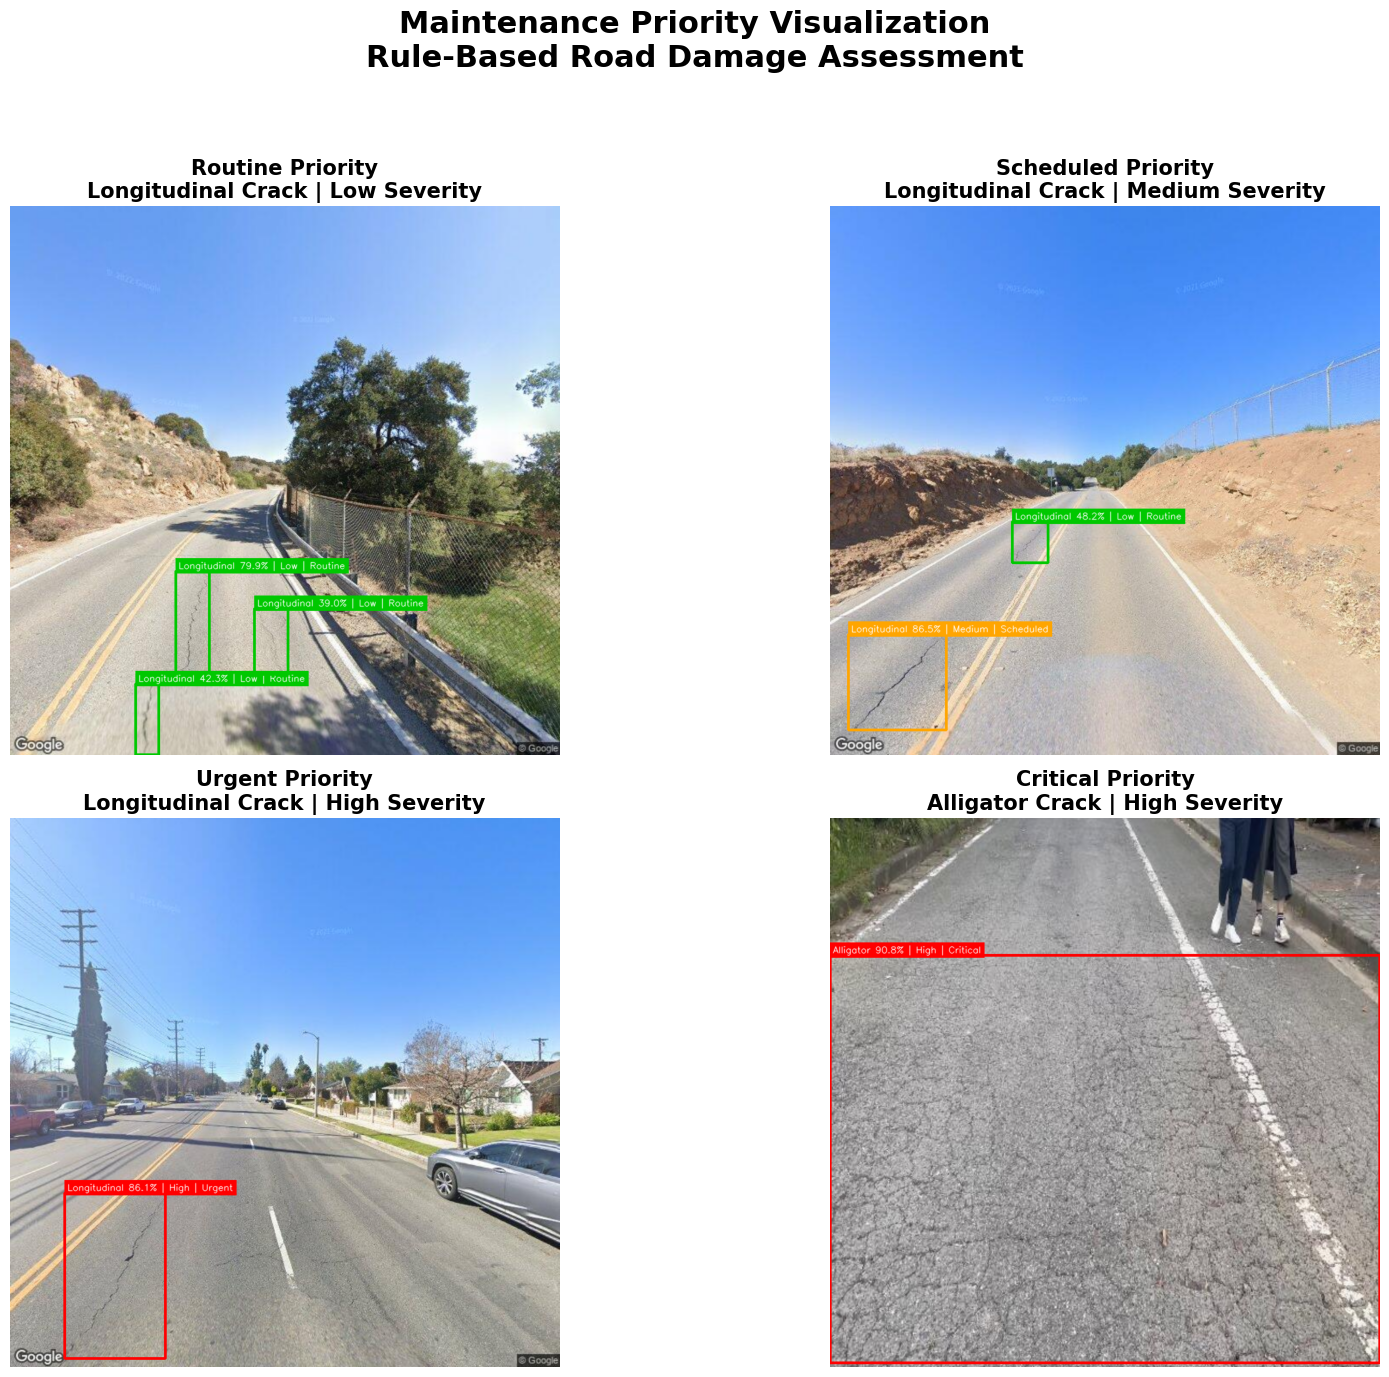


========== PRIORITY VISUALIZATION SAMPLES ==========


,Image Name,Damage Type,Severity,Maintenance Priority,Confidence (%),Damage Area (%),Annotated Image Path
0,United_States_004422.jpg,Longitudinal Crack,Low,Routine,79.93,1.2188,/kaggle/working/Severity_Maintenance_Prioritiz...
1,United_States_002902.jpg,Longitudinal Crack,Medium,Scheduled,86.52,3.1068,/kaggle/working/Severity_Maintenance_Prioritiz...
2,United_States_003632.jpg,Longitudinal Crack,High,Urgent,86.13,5.5209,/kaggle/working/Severity_Maintenance_Prioritiz...
3,China_MotorBike_001650.jpg,Alligator Crack,High,Critical,90.82,74.1406,/kaggle/working/Severity_Maintenance_Prioritiz...



========== VISUALIZATION VERIFICATION ==========
Total Annotated Images: 16
Severity Visualization Grid: True
Priority Visualization Grid: True
Visualization Samples CSV: True
Priority Samples CSV: True

========== SAVED OUTPUTS ==========
Annotated Images: /kaggle/working/Severity_Maintenance_Prioritization/Predictions/Annotated_Images
Severity Grid: /kaggle/working/Severity_Maintenance_Prioritization/Graphs/road_damage_severity_visualization.png
Priority Grid: /kaggle/working/Severity_Maintenance_Prioritization/Graphs/maintenance_priority_visualization.png
Reports: /kaggle/working/Severity_Maintenance_Prioritization/Reports

All visualization outputs saved successfully!

========== CELL 5 COMPLETED ==========


In [6]:

# ==========================================
# NOTEBOOK 06 - CELL 5
# Visualize Road Damage and Maintenance Priority
# ==========================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# ==========================================
# 1. Create Visualization Directory
# ==========================================

VISUALIZATION_DIR = (
    PREDICTIONS_DIR / "Annotated_Images"
)

VISUALIZATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("========== VISUALIZATION SETUP ==========")

print("Output Directory:", VISUALIZATION_DIR)

print("Available Damage Records:", len(damage_df))

print("Available Image Records:", len(image_summary_df))

# Verify updated Cell 4 results
assert len(damage_df) == 3289, (
    "Run corrected Cell 4 first!"
)

assert len(image_summary_df) == 2377

print("Updated FP16 Predictions: VERIFIED")

# ==========================================
# 2. Define Short Class Names
# ==========================================

SHORT_NAMES = {

    "Longitudinal Crack": "Longitudinal",

    "Transverse Crack": "Transverse",

    "Alligator Crack": "Alligator",

    "Pothole": "Pothole"
}

# ==========================================
# 3. Function to Draw Damage Annotations
# ==========================================

def annotate_damage_image(image_name):

    # Get all detections for selected image
    image_detections = damage_df[

        damage_df["Image Name"] == image_name

    ]

    # Load original image
    image_path = TEST_IMAGES_DIR / image_name

    image = cv2.imread(str(image_path))

    if image is None:

        raise ValueError(
            f"Cannot read image: {image_path}"
        )

    # Original image dimensions
    original_height, original_width = image.shape[:2]

    # Resize for consistent visualization
    display_width = 1000

    scale = display_width / original_width

    display_height = int(
        original_height * scale
    )

    annotated = cv2.resize(

        image,

        (display_width, display_height)
    )

    # Draw every detected damage
    for _, row in image_detections.iterrows():

        x1 = int(row["X1"] * scale)

        y1 = int(row["Y1"] * scale)

        x2 = int(row["X2"] * scale)

        y2 = int(row["Y2"] * scale)

        # Keep bounding boxes inside image
        x1 = max(0, min(x1, display_width - 1))

        x2 = max(0, min(x2, display_width - 1))

        y1 = max(0, min(y1, display_height - 1))

        y2 = max(0, min(y2, display_height - 1))

        severity = row["Severity"]

        priority = row["Maintenance Priority"]

        confidence = row["Confidence (%)"]

        damage_type = SHORT_NAMES[
            row["Damage Type"]
        ]

        color = SEVERITY_COLORS[severity]

        # Draw bounding box
        cv2.rectangle(

            annotated,

            (x1, y1),

            (x2, y2),

            color,

            3
        )

        # Prepare annotation label
        label = (

            f"{damage_type} {confidence:.1f}% | "

            f"{severity} | {priority}"
        )

        font = cv2.FONT_HERSHEY_SIMPLEX

        font_scale = 0.55

        thickness = 1

        (text_width, text_height), baseline = (
            cv2.getTextSize(

                label,

                font,

                font_scale,

                thickness
            )
        )

        # Keep label inside image boundaries
        label_x = max(

            0,

            min(
                x1,
                display_width - text_width - 10
            )
        )

        label_y = max(
            text_height + 10,
            y1
        )

        label_y = min(
            label_y,
            display_height - 5
        )

        # Draw label background
        cv2.rectangle(

            annotated,

            (
                label_x,
                label_y - text_height - 10
            ),

            (
                label_x + text_width + 10,
                label_y + 4
            ),

            color,

            -1
        )

        # Draw label text
        cv2.putText(

            annotated,

            label,

            (
                label_x + 5,
                label_y - 4
            ),

            font,

            font_scale,

            (255, 255, 255),

            thickness,

            cv2.LINE_AA
        )

    return annotated


# ==========================================
# 4. Select Representative Damage Samples
# ==========================================

# Select one image for each damage class
# and severity combination.

selected_samples = []

used_images = set()

severity_levels = [

    "Low",

    "Medium",

    "High"
]

for damage_type in EXPECTED_CLASSES.values():

    for severity in severity_levels:

        candidates = damage_df[

            (damage_df["Damage Type"] == damage_type)

            &

            (damage_df["Severity"] == severity)

        ].sort_values(

            "Confidence (%)",

            ascending=False
        )

        # Prefer unique images
        unused_candidates = candidates[

            ~candidates["Image Name"].isin(
                used_images
            )
        ]

        if len(unused_candidates) > 0:

            candidates = unused_candidates

        if len(candidates) > 0:

            sample = candidates.iloc[0]

            selected_samples.append({

                "Image Name": sample["Image Name"],

                "Damage Type": damage_type,

                "Severity": severity,

                "Maintenance Priority": sample[
                    "Maintenance Priority"
                ],

                "Confidence (%)": sample[
                    "Confidence (%)"
                ],

                "Damage Area (%)": sample[
                    "Damage Area (%)"
                ]
            })

            used_images.add(
                sample["Image Name"]
            )

samples_df = pd.DataFrame(selected_samples)

print("\n========== SELECTED VISUALIZATION SAMPLES ==========")

print("Total Selected Samples:", len(samples_df))

display(samples_df)

# ==========================================
# 5. Generate and Save Annotated Images
# ==========================================

annotated_paths = []

print("\n========== SAVING ANNOTATED IMAGES ==========")

for index, sample in samples_df.iterrows():

    image_name = sample["Image Name"]

    annotated_image = annotate_damage_image(
        image_name
    )

    damage_name = sample[
        "Damage Type"
    ].replace(" ", "_")

    severity = sample["Severity"]

    output_name = (

        f"{index + 1:02d}_"

        f"{damage_name}_"

        f"{severity}_"

        f"{Path(image_name).stem}.jpg"
    )

    output_path = (
        VISUALIZATION_DIR / output_name
    )

    success = cv2.imwrite(

        str(output_path),

        annotated_image
    )

    assert success, (
        f"Failed to save: {output_path}"
    )

    annotated_paths.append(
        str(output_path)
    )

    print("Saved:", output_name)

samples_df["Annotated Image Path"] = (
    annotated_paths
)

# ==========================================
# 6. Create Severity Visualization Grid
# ==========================================

fig, axes = plt.subplots(

    4,

    3,

    figsize=(21, 22)
)

fig.suptitle(

    "Road Damage Detection and Severity Assessment\n"

    "YOLOv8n-AdamW | RDD2022 Test Dataset",

    fontsize=22,

    fontweight="bold"
)

for row_index, damage_type in enumerate(

    EXPECTED_CLASSES.values()
):

    for col_index, severity in enumerate(

        severity_levels
    ):

        ax = axes[row_index, col_index]

        sample = samples_df[

            (samples_df["Damage Type"] == damage_type)

            &

            (samples_df["Severity"] == severity)
        ]

        if len(sample) == 0:

            ax.text(

                0.5,

                0.5,

                "No sample available",

                ha="center",

                va="center"
            )

            ax.axis("off")

            continue

        sample = sample.iloc[0]

        image = cv2.imread(

            sample["Annotated Image Path"]
        )

        image_rgb = cv2.cvtColor(

            image,

            cv2.COLOR_BGR2RGB
        )

        ax.imshow(image_rgb)

        ax.set_title(

            f"{damage_type} | {severity}\n"

            f"Priority: "
            f"{sample['Maintenance Priority']}"

            f" | Confidence: "
            f"{sample['Confidence (%)']:.1f}%",

            fontsize=12,

            fontweight="bold"
        )

        ax.axis("off")

plt.tight_layout(

    rect=[0, 0, 1, 0.96]
)

grid_path = (

    GRAPHS_DIR /

    "road_damage_severity_visualization.png"
)

plt.savefig(

    grid_path,

    dpi=150,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# ==========================================
# 7. Visualize Maintenance Priority Samples
# ==========================================

priority_levels = [

    "Routine",

    "Scheduled",

    "Urgent",

    "Critical"
]

priority_sample_records = []

fig, axes = plt.subplots(

    2,

    2,

    figsize=(18, 14)
)

fig.suptitle(

    "Maintenance Priority Visualization\n"

    "Rule-Based Road Damage Assessment",

    fontsize=22,

    fontweight="bold"
)

for ax, priority in zip(

    axes.flatten(),

    priority_levels
):

    # Select images with this highest priority
    priority_images = image_summary_df[

        image_summary_df["Highest Priority"]
        == priority

    ]["Image Name"]

    candidates = damage_df[

        (damage_df["Maintenance Priority"] == priority)

        &

        (damage_df["Image Name"].isin(priority_images))

    ].sort_values(

        "Confidence (%)",

        ascending=False
    )

    if len(candidates) == 0:

        ax.text(

            0.5,

            0.5,

            "No sample available",

            ha="center",

            va="center"
        )

        ax.axis("off")

        continue

    sample = candidates.iloc[0]

    annotated_image = annotate_damage_image(

        sample["Image Name"]
    )

    # Save priority-specific example
    output_path = (

        VISUALIZATION_DIR /

        f"Priority_{priority}_"
        f"{Path(sample['Image Name']).stem}.jpg"
    )

    assert cv2.imwrite(

        str(output_path),

        annotated_image
    )

    priority_sample_records.append({

        "Image Name": sample["Image Name"],

        "Damage Type": sample["Damage Type"],

        "Severity": sample["Severity"],

        "Maintenance Priority": priority,

        "Confidence (%)": sample["Confidence (%)"],

        "Damage Area (%)": sample["Damage Area (%)"],

        "Annotated Image Path": str(output_path)
    })

    image_rgb = cv2.cvtColor(

        annotated_image,

        cv2.COLOR_BGR2RGB
    )

    ax.imshow(image_rgb)

    ax.set_title(

        f"{priority} Priority\n"

        f"{sample['Damage Type']} | "

        f"{sample['Severity']} Severity",

        fontsize=15,

        fontweight="bold"
    )

    ax.axis("off")

plt.tight_layout(

    rect=[0, 0, 1, 0.94]
)

priority_grid_path = (

    GRAPHS_DIR /

    "maintenance_priority_visualization.png"
)

plt.savefig(

    priority_grid_path,

    dpi=150,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# ==========================================
# 8. Save Visualization Sample Reports
# ==========================================

samples_df.to_csv(

    REPORTS_DIR /

    "visualization_samples.csv",

    index=False
)

priority_samples_df = pd.DataFrame(
    priority_sample_records
)

priority_samples_df.to_csv(

    REPORTS_DIR /

    "priority_visualization_samples.csv",

    index=False
)

print("\n========== PRIORITY VISUALIZATION SAMPLES ==========")

display(priority_samples_df)

# ==========================================
# 9. Verify All Outputs
# ==========================================

print("\n========== VISUALIZATION VERIFICATION ==========")

annotated_files = list(

    VISUALIZATION_DIR.glob("*.jpg")
)

print(

    "Total Annotated Images:",

    len(annotated_files)
)

print(

    "Severity Visualization Grid:",

    grid_path.exists()
)

print(

    "Priority Visualization Grid:",

    priority_grid_path.exists()
)

print(

    "Visualization Samples CSV:",

    (

        REPORTS_DIR /

        "visualization_samples.csv"

    ).exists()
)

print(

    "Priority Samples CSV:",

    (

        REPORTS_DIR /

        "priority_visualization_samples.csv"

    ).exists()
)

assert grid_path.exists()

assert priority_grid_path.exists()

assert len(annotated_files) > 0

assert all(

    Path(path).exists()

    for path in annotated_paths
)

# ==========================================
# 10. Final Output Summary
# ==========================================

print("\n========== SAVED OUTPUTS ==========")

print("Annotated Images:", VISUALIZATION_DIR)

print("Severity Grid:", grid_path)

print("Priority Grid:", priority_grid_path)

print("Reports:", REPORTS_DIR)

print("\nAll visualization outputs saved successfully!")

print("\n========== CELL 5 COMPLETED ==========")


## Step 6: Generate Ranked Maintenance Priority Report

Generate an image-level maintenance prioritization
report using the predicted road damage severity and
assigned maintenance priority.

The ranking is based on:

1. Highest maintenance priority score
2. Number of critical damage detections
3. Number of high-severity damage detections
4. Total number of detected damages
5. Maximum bounding box area among the highest
   priority detections

Assign a recommended maintenance inspection action
to each priority category:

- Critical: Immediate field inspection
- Urgent: Prompt field inspection
- Scheduled: Planned maintenance inspection
- Routine: Routine monitoring and inspection

Images with no detected damage are placed in a
separate manual review report instead of being
classified as damage-free roads.

Generate and save:

- Ranked maintenance priority report
- Manual review report
- Image-level priority distribution
- Maintenance summary
- Priority distribution and ranking visualizations

Note: Each image is treated as an inspection unit.
Actual road segment ranking requires GPS coordinates
or road segment identifiers.

The proposed severity and priority rules provide
decision support and require field validation before
real-world maintenance decisions.

========== MAINTENANCE REPORT SETUP ==========
Total Damage Detections: 3289
Total Road Images: 2377
Cell 4 and Cell 5 Results: VERIFIED
Output Directory: /kaggle/working/Severity_Maintenance_Prioritization/Maintenance_Ranking

========== IMAGE CLASSIFICATION ==========
Images with Detected Damage: 1755
Images Requiring Manual Review: 622

========== TOP 10 MAINTENANCE PRIORITIES ==========


,Rank,Image Name,Highest Priority,Highest Severity,Highest Priority Damage Type,Total Detections,Critical Damage Count,Max Priority Damage Area (%)
0,1,China_MotorBike_000545.jpg,Critical,High,Alligator Crack,4,3,35.1284
1,2,Japan_006794.jpg,Critical,High,Alligator Crack,4,3,44.3268
2,3,United_States_003180.jpg,Critical,High,Alligator Crack,4,3,36.9001
3,4,Japan_010309.jpg,Critical,High,Alligator Crack,4,3,32.6492
4,5,Japan_005381.jpg,Critical,High,Alligator Crack,3,3,31.6418
5,6,United_States_003282.jpg,Critical,High,Alligator Crack,3,3,31.2151
6,7,Japan_003753.jpg,Critical,High,Alligator Crack,3,3,28.3521
7,8,Japan_007961.jpg,Critical,High,Alligator Crack,3,3,28.2942
8,9,Japan_004450.jpg,Critical,High,Alligator Crack,3,3,25.1698
9,10,Japan_002394.jpg,Critical,High,Alligator Crack,3,3,23.5852



========== MANUAL REVIEW SAMPLE ==========


,Image Name,Detection Status,Total Detections,Highest Priority,Priority Score,Recommended Action,Assessment Status,Image Path
0,China_Drone_000094.jpg,No Damage Detected,0,Not Assessed,0,Manual inspection required; no damage detected...,Not assessed; absence of detection does not es...,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...
1,China_Drone_000160.jpg,No Damage Detected,0,Not Assessed,0,Manual inspection required; no damage detected...,Not assessed; absence of detection does not es...,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...
2,China_Drone_000182.jpg,No Damage Detected,0,Not Assessed,0,Manual inspection required; no damage detected...,Not assessed; absence of detection does not es...,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...
3,China_Drone_000192.jpg,No Damage Detected,0,Not Assessed,0,Manual inspection required; no damage detected...,Not assessed; absence of detection does not es...,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...
4,China_Drone_000194.jpg,No Damage Detected,0,Not Assessed,0,Manual inspection required; no damage detected...,Not assessed; absence of detection does not es...,/kaggle/input/datasets/ammritkumaar/rdd2022-pr...



========== IMAGE-LEVEL PRIORITY DISTRIBUTION ==========


,Maintenance Priority,Images,Percentage (%)
0,Critical,456,19.18
1,Urgent,511,21.50
2,Scheduled,439,18.47
3,Routine,349,14.68
4,Not Assessed,622,26.17



========== DAMAGE-LEVEL PRIORITY DISTRIBUTION ==========


,Maintenance Priority,Damage Instances,Percentage (%)
0,Critical,549,16.69
1,Urgent,759,23.08
2,Scheduled,864,26.27
3,Routine,1117,33.96



========== SEVERITY DISTRIBUTION BY CLASS ==========


Severity,Low,Medium,High,Total
Damage Type,,,,
Longitudinal Crack,719,410,454,1583
Transverse Crack,398,197,117,712
Alligator Crack,61,128,529,718
Pothole,196,60,20,276


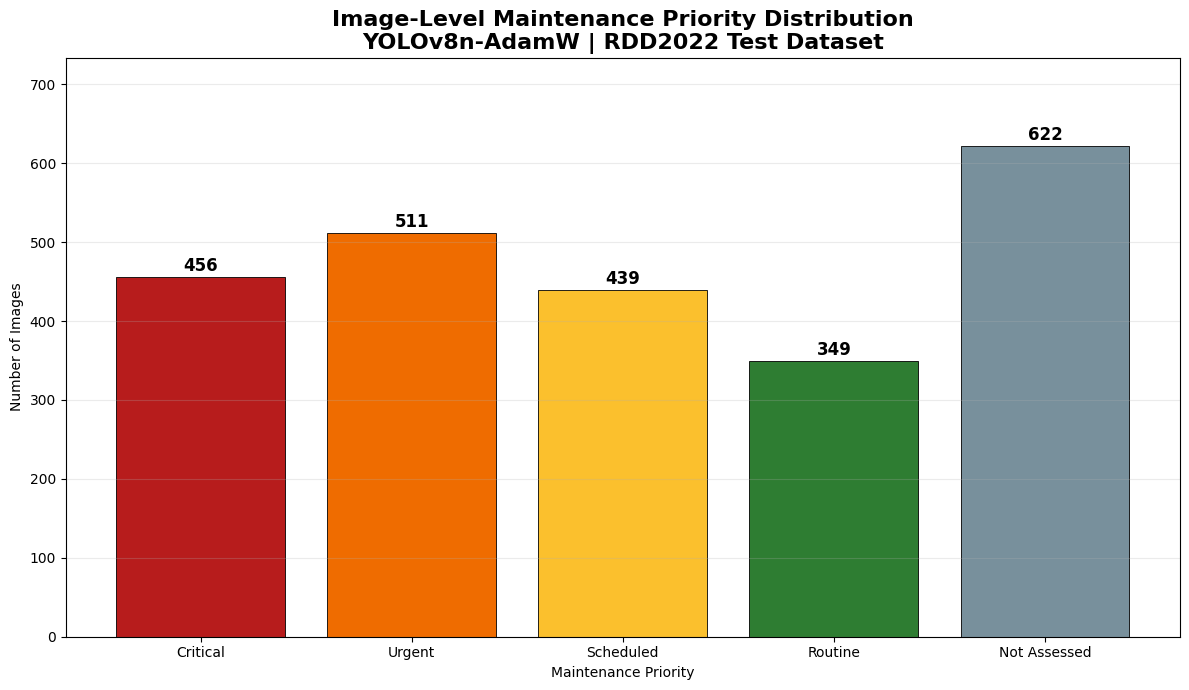

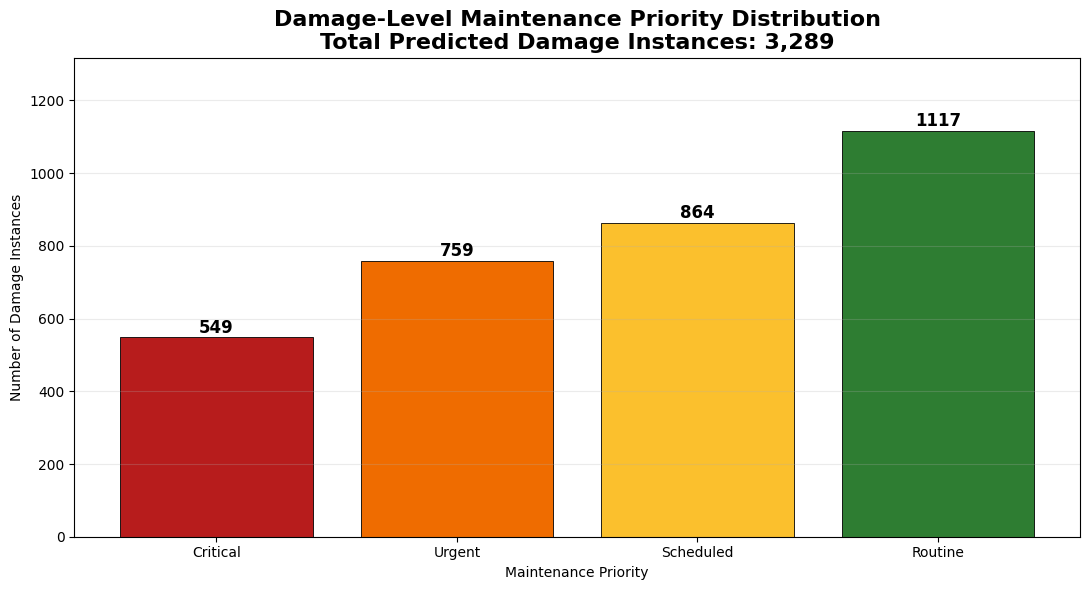

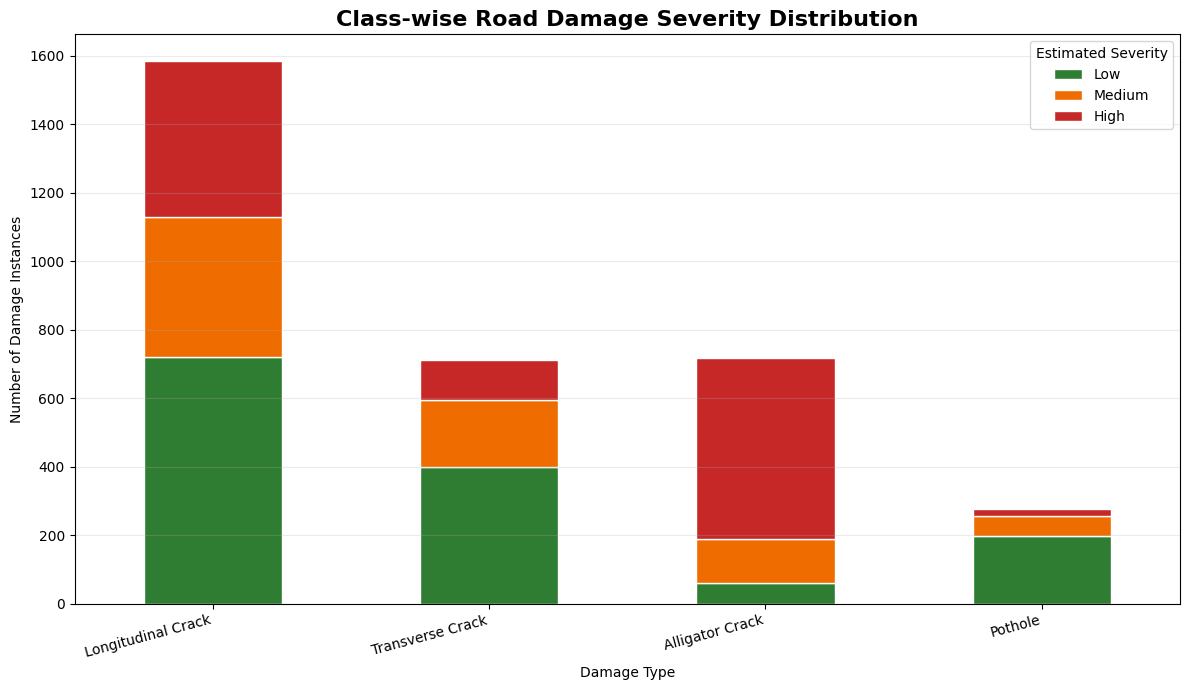

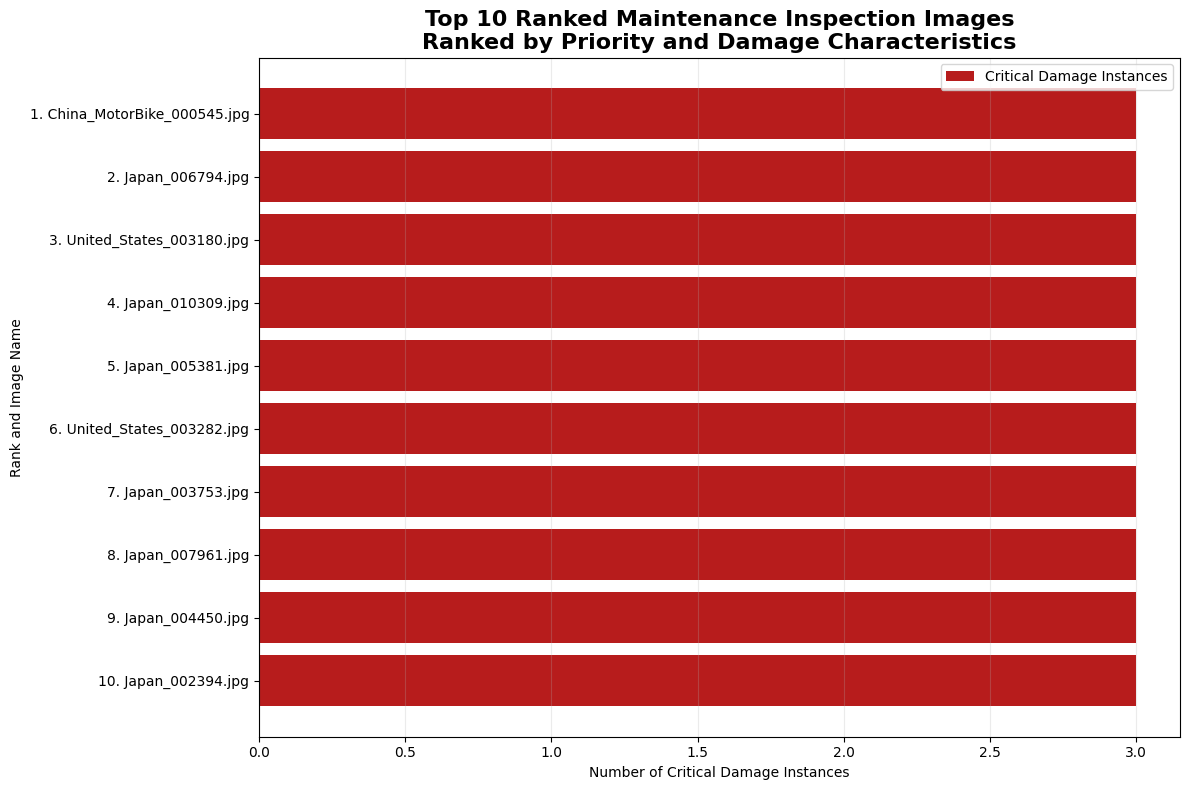


========== REPORT VERIFICATION ==========
Verified: ranked_maintenance_report.csv
Verified: manual_review_images.csv
Verified: image_priority_distribution.csv
Verified: damage_priority_distribution.csv
Verified: classwise_severity_distribution.csv
Verified: top10_maintenance_priorities.csv
Verified: maintenance_summary.json

========== GRAPH VERIFICATION ==========
Verified: image_priority_distribution.png
Verified: damage_priority_distribution.png
Verified: classwise_severity_distribution.png
Verified: top10_maintenance_priority.png

========== FINAL MAINTENANCE SUMMARY ==========
Total Test Images: 2377
Total Damage Detections: 3289
Ranked Maintenance Images: 1755
Manual Review Images: 622
Critical Damage Instances: 549
Critical Priority Images: 456
Urgent Priority Images: 511
Scheduled Priority Images: 439
Routine Priority Images: 349

Maintenance Reports: /kaggle/working/Severity_Maintenance_Prioritization/Maintenance_Ranking
Graphs Directory: /kaggle/working/Severity_Maintenance_

In [7]:

# ==========================================
# NOTEBOOK 06 - CELL 6
# Ranked Maintenance Priority Report
# ==========================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# ==========================================
# 1. Verify Previous Results
# ==========================================

print("========== MAINTENANCE REPORT SETUP ==========")

assert len(damage_df) == 3289

assert len(image_summary_df) == 2377

assert image_summary_df["Total Detections"].sum() == 3289

print("Total Damage Detections:", len(damage_df))

print("Total Road Images:", len(image_summary_df))

print("Cell 4 and Cell 5 Results: VERIFIED")

# ==========================================
# 2. Create Maintenance Report Directory
# ==========================================

MAINTENANCE_DIR = (

    PROJECT_DIR / "Maintenance_Ranking"
)

MAINTENANCE_DIR.mkdir(

    parents=True,

    exist_ok=True
)

print("Output Directory:", MAINTENANCE_DIR)

# ==========================================
# 3. Define Recommended Maintenance Actions
# ==========================================

MAINTENANCE_ACTIONS = {

    "Critical": (
        "Immediate field inspection and "
        "maintenance assessment"
    ),

    "Urgent": (
        "Prompt field inspection and "
        "repair planning"
    ),

    "Scheduled": (
        "Include in planned maintenance inspection"
    ),

    "Routine": (
        "Routine monitoring and inspection"
    ),

    "Not Assessed": (
        "Manual inspection required; "
        "no damage detected by model"
    )
}

# ==========================================
# 4. Separate Detected and Undetected Images
# ==========================================

detected_images_df = image_summary_df[

    image_summary_df["Total Detections"] > 0

].copy()

manual_review_df = image_summary_df[

    image_summary_df["Total Detections"] == 0

].copy()

print("\n========== IMAGE CLASSIFICATION ==========")

print(

    "Images with Detected Damage:",

    len(detected_images_df)
)

print(

    "Images Requiring Manual Review:",

    len(manual_review_df)
)

assert len(detected_images_df) == 1755

assert len(manual_review_df) == 622

assert (

    len(detected_images_df)

    + len(manual_review_df)

    == len(image_summary_df)
)

# ==========================================
# 5. Calculate Additional Ranking Information
# ==========================================

# Get highest priority score for every image
highest_priority_scores = (

    damage_df.groupby("Image Name")[
        "Priority Score"
    ].transform("max")
)

# Select detections matching the highest
# priority of their respective image

highest_priority_damages = damage_df[

    damage_df["Priority Score"]

    == highest_priority_scores

].copy()

# Maximum bounding box area among the
# highest priority detections

max_priority_area = (

    highest_priority_damages

    .groupby("Image Name")["Damage Area (%)"]

    .max()

    .rename("Max Priority Damage Area (%)")

    .reset_index()
)

detected_images_df = detected_images_df.merge(

    max_priority_area,

    on="Image Name",

    how="left",

    validate="one_to_one"
)

assert detected_images_df[

    "Max Priority Damage Area (%)"

].notna().all()

# ==========================================
# 6. Generate Maintenance Ranking
# ==========================================

# Ranking order:
# 1. Highest priority score
# 2. Critical damage count
# 3. High severity damage count
# 4. Total damage detections
# 5. Maximum priority damage area
# 6. Image name for deterministic tie-breaking

ranked_maintenance_df = (

    detected_images_df.sort_values(

        by=[

            "Priority Score",

            "Critical Damage Count",

            "High Severity Count",

            "Total Detections",

            "Max Priority Damage Area (%)",

            "Image Name"
        ],

        ascending=[

            False,

            False,

            False,

            False,

            False,

            True
        ]
    )

    .reset_index(drop=True)
)

# Assign rank
ranked_maintenance_df.insert(

    0,

    "Rank",

    np.arange(

        1,

        len(ranked_maintenance_df) + 1
    )
)

# Add recommended action
ranked_maintenance_df["Recommended Action"] = (

    ranked_maintenance_df["Highest Priority"]

    .map(MAINTENANCE_ACTIONS)
)

# Add assessment status
ranked_maintenance_df["Assessment Status"] = (

    "Model-based assessment; field validation required"
)

# ==========================================
# 7. Organize Final Report Columns
# ==========================================

ranking_columns = [

    "Rank",

    "Image Name",

    "Highest Priority",

    "Priority Score",

    "Highest Severity",

    "Highest Priority Damage Type",

    "Total Detections",

    "Critical Damage Count",

    "High Severity Count",

    "Medium Severity Count",

    "Low Severity Count",

    "Max Priority Damage Area (%)",

    "Average Confidence (%)",

    "Recommended Action",

    "Assessment Status",

    "Image Path"
]

ranked_maintenance_df = (

    ranked_maintenance_df[ranking_columns]
)

print("\n========== TOP 10 MAINTENANCE PRIORITIES ==========")

display(

    ranked_maintenance_df[[

        "Rank",

        "Image Name",

        "Highest Priority",

        "Highest Severity",

        "Highest Priority Damage Type",

        "Total Detections",

        "Critical Damage Count",

        "Max Priority Damage Area (%)"

    ]].head(10)
)

# ==========================================
# 8. Prepare Manual Review Report
# ==========================================

manual_review_df = (

    manual_review_df.sort_values("Image Name")

    .reset_index(drop=True)
)

manual_review_df["Recommended Action"] = (

    MAINTENANCE_ACTIONS["Not Assessed"]
)

manual_review_df["Assessment Status"] = (

    "Not assessed; absence of detection "

    "does not establish absence of damage"
)

manual_review_df = manual_review_df[[

    "Image Name",

    "Detection Status",

    "Total Detections",

    "Highest Priority",

    "Priority Score",

    "Recommended Action",

    "Assessment Status",

    "Image Path"
]]

print("\n========== MANUAL REVIEW SAMPLE ==========")

display(manual_review_df.head(5))

# ==========================================
# 9. Image-Level Maintenance Distribution
# ==========================================

priority_order = [

    "Critical",

    "Urgent",

    "Scheduled",

    "Routine",

    "Not Assessed"
]

image_priority_distribution = (

    image_summary_df["Highest Priority"]

    .value_counts()

    .reindex(

        priority_order,

        fill_value=0
    )

    .rename_axis("Maintenance Priority")

    .reset_index(name="Images")
)

image_priority_distribution["Percentage (%)"] = (

    image_priority_distribution["Images"]

    / len(image_summary_df)

    * 100

).round(2)

print("\n========== IMAGE-LEVEL PRIORITY DISTRIBUTION ==========")

display(image_priority_distribution)

assert image_priority_distribution["Images"].sum() == 2377

# ==========================================
# 10. Damage-Level Priority Distribution
# ==========================================

damage_priority_distribution = (

    damage_df["Maintenance Priority"]

    .value_counts()

    .reindex(

        ["Critical", "Urgent", "Scheduled", "Routine"],

        fill_value=0
    )

    .rename_axis("Maintenance Priority")

    .reset_index(name="Damage Instances")
)

damage_priority_distribution["Percentage (%)"] = (

    damage_priority_distribution["Damage Instances"]

    / len(damage_df)

    * 100

).round(2)

print("\n========== DAMAGE-LEVEL PRIORITY DISTRIBUTION ==========")

display(damage_priority_distribution)

assert (

    damage_priority_distribution[

        "Damage Instances"

    ].sum() == 3289
)

# ==========================================
# 11. Create Severity Distribution by Class
# ==========================================

severity_by_class = pd.crosstab(

    damage_df["Damage Type"],

    damage_df["Severity"]
)

severity_by_class = severity_by_class.reindex(

    index=list(EXPECTED_CLASSES.values()),

    columns=["Low", "Medium", "High"],

    fill_value=0
)

severity_by_class["Total"] = (

    severity_by_class.sum(axis=1)
)

print("\n========== SEVERITY DISTRIBUTION BY CLASS ==========")

display(severity_by_class)

assert severity_by_class["Total"].sum() == 3289

# ==========================================
# 12. Plot Image-Level Priority Distribution
# ==========================================

priority_colors = [

    "#B71C1C",  # Critical

    "#EF6C00",  # Urgent

    "#FBC02D",  # Scheduled

    "#2E7D32",  # Routine

    "#78909C"   # Not Assessed
]

fig, ax = plt.subplots(

    figsize=(12, 7)
)

bars = ax.bar(

    image_priority_distribution[
        "Maintenance Priority"
    ],

    image_priority_distribution["Images"],

    color=priority_colors,

    edgecolor="black",

    linewidth=0.6
)

for bar, value in zip(

    bars,

    image_priority_distribution["Images"]
):

    ax.text(

        bar.get_x() + bar.get_width() / 2,

        bar.get_height() + 8,

        str(value),

        ha="center",

        fontsize=12,

        fontweight="bold"
    )

ax.set_title(

    "Image-Level Maintenance Priority Distribution\n"

    "YOLOv8n-AdamW | RDD2022 Test Dataset",

    fontsize=16,

    fontweight="bold"
)

ax.set_xlabel("Maintenance Priority")

ax.set_ylabel("Number of Images")

ax.set_ylim(

    0,

    image_priority_distribution["Images"].max() * 1.18
)

ax.grid(

    axis="y",

    alpha=0.25
)

plt.tight_layout()

image_priority_graph = (

    GRAPHS_DIR /

    "image_priority_distribution.png"
)

plt.savefig(

    image_priority_graph,

    dpi=200,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# ==========================================
# 13. Plot Damage-Level Priority Distribution
# ==========================================

fig, ax = plt.subplots(

    figsize=(11, 6)
)

bars = ax.bar(

    damage_priority_distribution[
        "Maintenance Priority"
    ],

    damage_priority_distribution[
        "Damage Instances"
    ],

    color=priority_colors[:4],

    edgecolor="black",

    linewidth=0.6
)

for bar, value in zip(

    bars,

    damage_priority_distribution[
        "Damage Instances"
    ]
):

    ax.text(

        bar.get_x() + bar.get_width() / 2,

        bar.get_height() + 12,

        str(value),

        ha="center",

        fontsize=12,

        fontweight="bold"
    )

ax.set_title(

    "Damage-Level Maintenance Priority Distribution\n"

    "Total Predicted Damage Instances: 3,289",

    fontsize=16,

    fontweight="bold"
)

ax.set_xlabel("Maintenance Priority")

ax.set_ylabel("Number of Damage Instances")

ax.set_ylim(

    0,

    damage_priority_distribution[

        "Damage Instances"

    ].max() * 1.18
)

ax.grid(

    axis="y",

    alpha=0.25
)

plt.tight_layout()

damage_priority_graph = (

    GRAPHS_DIR /

    "damage_priority_distribution.png"
)

plt.savefig(

    damage_priority_graph,

    dpi=200,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# ==========================================
# 14. Plot Class-wise Severity Distribution
# ==========================================

fig, ax = plt.subplots(

    figsize=(12, 7)
)

severity_by_class[[

    "Low",

    "Medium",

    "High"

]].plot(

    kind="bar",

    stacked=True,

    ax=ax,

    color=[

        "#2E7D32",

        "#EF6C00",

        "#C62828"
    ],

    edgecolor="white"
)

ax.set_title(

    "Class-wise Road Damage Severity Distribution",

    fontsize=16,

    fontweight="bold"
)

ax.set_xlabel("Damage Type")

ax.set_ylabel("Number of Damage Instances")

ax.set_xticklabels(

    severity_by_class.index,

    rotation=15,

    ha="right"
)

ax.legend(title="Estimated Severity")

ax.grid(

    axis="y",

    alpha=0.25
)

plt.tight_layout()

class_severity_graph = (

    GRAPHS_DIR /

    "classwise_severity_distribution.png"
)

plt.savefig(

    class_severity_graph,

    dpi=200,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# ==========================================
# 15. Visualize Top 10 Ranked Images
# ==========================================

top10 = ranked_maintenance_df.head(10).copy()

top10["Display Label"] = (

    top10["Rank"].astype(str)

    + ". "

    + top10["Image Name"]
)

fig, ax = plt.subplots(

    figsize=(12, 8)
)

ax.barh(

    top10["Display Label"],

    top10["Critical Damage Count"],

    color="#B71C1C",

    label="Critical Damage Instances"
)

ax.invert_yaxis()

ax.set_title(

    "Top 10 Ranked Maintenance Inspection Images\n"

    "Ranked by Priority and Damage Characteristics",

    fontsize=16,

    fontweight="bold"
)

ax.set_xlabel("Number of Critical Damage Instances")

ax.set_ylabel("Rank and Image Name")

ax.legend()

ax.grid(

    axis="x",

    alpha=0.25
)

plt.tight_layout()

top10_graph = (

    GRAPHS_DIR /

    "top10_maintenance_priority.png"
)

plt.savefig(

    top10_graph,

    dpi=200,

    bbox_inches="tight"
)

plt.show()

plt.close(fig)

# ==========================================
# 16. Save All Maintenance Reports
# ==========================================

ranked_maintenance_df.to_csv(

    MAINTENANCE_DIR /

    "ranked_maintenance_report.csv",

    index=False
)

manual_review_df.to_csv(

    MAINTENANCE_DIR /

    "manual_review_images.csv",

    index=False
)

image_priority_distribution.to_csv(

    MAINTENANCE_DIR /

    "image_priority_distribution.csv",

    index=False
)

damage_priority_distribution.to_csv(

    MAINTENANCE_DIR /

    "damage_priority_distribution.csv",

    index=False
)

severity_by_class.to_csv(

    MAINTENANCE_DIR /

    "classwise_severity_distribution.csv"
)

top10.drop(

    columns=["Display Label"]

).to_csv(

    MAINTENANCE_DIR /

    "top10_maintenance_priorities.csv",

    index=False
)

# ==========================================
# 17. Generate Final Maintenance Summary
# ==========================================

image_priority_counts = {

    str(row["Maintenance Priority"]):

    int(row["Images"])

    for _, row in

    image_priority_distribution.iterrows()
}

damage_priority_counts = {

    str(row["Maintenance Priority"]):

    int(row["Damage Instances"])

    for _, row in

    damage_priority_distribution.iterrows()
}

severity_counts = {

    str(row["Severity"]):

    int(row["Detections"])

    for _, row in

    severity_distribution.iterrows()
}

maintenance_summary = {

    "model": "YOLOv8n-AdamW",

    "completed_training_epochs": 16,

    "total_test_images": int(

        len(image_summary_df)
    ),

    "total_damage_detections": int(

        len(damage_df)
    ),

    "ranked_images": int(

        len(ranked_maintenance_df)
    ),

    "manual_review_images": int(

        len(manual_review_df)
    ),

    "image_level_priority_counts":

        image_priority_counts,

    "damage_level_priority_counts":

        damage_priority_counts,

    "severity_counts":

        severity_counts,

    "confidence_threshold": 0.25,

    "nms_iou_threshold": 0.70,

    "precision_mode": "FP16",

    "ranking_unit": "Individual road image",

    "ranking_method": [

        "Highest priority score",

        "Critical damage count",

        "High severity damage count",

        "Total detections",

        "Maximum highest-priority bounding box area",

        "Image name tie-breaker"
    ],

    "severity_method": (

        "Class-specific bounding box area thresholds"
    ),

    "maintenance_priority_method": (

        "Class-specific severity-to-priority rules"
    ),

    "limitations": [

        "No ground-truth severity labels available",

        "Bounding box area is not physical damage area",

        "No detection does not mean damage-free road",

        "Image ranking is not geographic road segment ranking",

        "Field validation is required before maintenance"
    ]
}

with open(

    MAINTENANCE_DIR / "maintenance_summary.json",

    "w"

) as file:

    json.dump(

        maintenance_summary,

        file,

        indent=4
    )

# ==========================================
# 18. Final Verification
# ==========================================

assert len(ranked_maintenance_df) == 1755

assert len(manual_review_df) == 622

assert (

    ranked_maintenance_df["Total Detections"].sum()

    == 3289
)

assert ranked_maintenance_df["Rank"].is_unique

assert ranked_maintenance_df[

    "Priority Score"

].is_monotonic_decreasing

assert (

    ranked_maintenance_df["Critical Damage Count"].sum()

    == 549
)

assert set(

    ranked_maintenance_df["Image Name"]

).isdisjoint(

    set(manual_review_df["Image Name"])
)

required_reports = [

    "ranked_maintenance_report.csv",

    "manual_review_images.csv",

    "image_priority_distribution.csv",

    "damage_priority_distribution.csv",

    "classwise_severity_distribution.csv",

    "top10_maintenance_priorities.csv",

    "maintenance_summary.json"
]

print("\n========== REPORT VERIFICATION ==========")

for filename in required_reports:

    file_path = MAINTENANCE_DIR / filename

    assert file_path.exists()

    print("Verified:", filename)

required_graphs = [

    image_priority_graph,

    damage_priority_graph,

    class_severity_graph,

    top10_graph
]

print("\n========== GRAPH VERIFICATION ==========")

for graph_path in required_graphs:

    assert graph_path.exists()

    print("Verified:", graph_path.name)

# ==========================================
# 19. Display Final Summary
# ==========================================

print("\n========== FINAL MAINTENANCE SUMMARY ==========")

print("Total Test Images:", len(image_summary_df))

print("Total Damage Detections:", len(damage_df))

print("Ranked Maintenance Images:", len(ranked_maintenance_df))

print("Manual Review Images:", len(manual_review_df))

print("Critical Damage Instances:", 549)

print(

    "Critical Priority Images:",

    image_priority_counts["Critical"]
)

print(

    "Urgent Priority Images:",

    image_priority_counts["Urgent"]
)

print(

    "Scheduled Priority Images:",

    image_priority_counts["Scheduled"]
)

print(

    "Routine Priority Images:",

    image_priority_counts["Routine"]
)

print("\nMaintenance Reports:", MAINTENANCE_DIR)

print("Graphs Directory:", GRAPHS_DIR)

print("\nAll maintenance reports saved successfully!")

print("\n========== CELL 6 COMPLETED ==========")


## Step 7: Final Backup and Export

Create a complete backup of the severity estimation
and maintenance prioritization pipeline.

Include the following outputs:

- Final trained YOLOv8n-AdamW model
- Final model evaluation summary
- Severity estimation and maintenance priority rules
- Damage-level assessment reports
- Image-level assessment reports
- Prediction consistency verification
- Annotated road damage images
- Severity and priority visualization grids
- Ranked maintenance priority reports
- Manual review reports
- Final maintenance summary and graphs

Compress all required outputs into a ZIP archive
for project submission, documentation, and future use.

Verify the archive contents and ensure all essential
reports, model weights, and visualizations are included.

Note: The original RDD2022 dataset is not duplicated
in the backup to avoid unnecessary storage usage.

In [8]:

# ==========================================
# NOTEBOOK 06 - CELL 7
# Final Backup and Export
# ==========================================

import os
import json
import shutil
import zipfile

from pathlib import Path

# ==========================================
# 1. Verify Final Project Outputs
# ==========================================

print("========== FINAL BACKUP SETUP ==========")

assert PROJECT_DIR.exists()

assert MODEL_PATH.exists()

assert SUMMARY_PATH.exists()

assert MAINTENANCE_DIR.exists()

assert GRAPHS_DIR.exists()

assert REPORTS_DIR.exists()

assert VISUALIZATION_DIR.exists()

print("Project Directory:", PROJECT_DIR)

print("Final Model:", MODEL_PATH)

print("Final Evaluation Summary:", SUMMARY_PATH)

print("All Source Directories: VERIFIED")

# ==========================================
# 2. Create Backup Directory
# ==========================================

BACKUP_DIR = (

    WORK_DIR /

    "Severity_Maintenance_Prioritization_Backup"
)

BACKUP_DIR.mkdir(

    parents=True,

    exist_ok=True
)

print("\nBackup Directory:", BACKUP_DIR)

# ==========================================
# 3. Copy Complete Notebook 06 Outputs
# ==========================================

BACKUP_PROJECT_DIR = (

    BACKUP_DIR /

    "Severity_Maintenance_Prioritization"
)

shutil.copytree(

    PROJECT_DIR,

    BACKUP_PROJECT_DIR,

    dirs_exist_ok=True
)

print("\n========== COPYING PROJECT OUTPUTS ==========")

print("Copied: Severity and Maintenance Outputs")

# ==========================================
# 4. Copy Final Trained Model
# ==========================================

BACKUP_MODEL_DIR = (

    BACKUP_DIR /

    "Final_Model"
)

BACKUP_MODEL_DIR.mkdir(

    parents=True,

    exist_ok=True
)

BACKUP_MODEL_PATH = (

    BACKUP_MODEL_DIR /

    "best_model.pt"
)

shutil.copy2(

    MODEL_PATH,

    BACKUP_MODEL_PATH
)

assert BACKUP_MODEL_PATH.exists()

print("\n========== MODEL BACKUP ==========")

print("Copied: best_model.pt")

print(

    "Model Size:",

    round(

        BACKUP_MODEL_PATH.stat().st_size

        / (1024 ** 2),

        2
    ),

    "MB"
)

# Copy model selection information

MODEL_SELECTION_PATH = (

    MODEL_PATH.parent /

    "model_selection.json"
)

if MODEL_SELECTION_PATH.exists():

    shutil.copy2(

        MODEL_SELECTION_PATH,

        BACKUP_MODEL_DIR /

        "model_selection.json"
    )

    print("Copied: model_selection.json")

# ==========================================
# 5. Copy Final Evaluation Summary
# ==========================================

BACKUP_EVALUATION_DIR = (

    BACKUP_DIR /

    "Final_Model_Evaluation"
)

BACKUP_EVALUATION_DIR.mkdir(

    parents=True,

    exist_ok=True
)

# Copy complete final evaluation summary folder

shutil.copytree(

    SUMMARY_PATH.parent,

    BACKUP_EVALUATION_DIR,

    dirs_exist_ok=True
)

print("\n========== EVALUATION BACKUP ==========")

print("Copied: Final Model Evaluation Summary")

# Copy detailed test evaluation outputs
# if available in Notebook 05 saved outputs

TEST_EVALUATION_SOURCE = (

    FINAL_EVAL_DIR /

    "AdamW_Final_Test"
)

if TEST_EVALUATION_SOURCE.exists():

    shutil.copytree(

        TEST_EVALUATION_SOURCE,

        BACKUP_EVALUATION_DIR /

        "AdamW_Final_Test",

        dirs_exist_ok=True
    )

    print("Copied: Detailed Final Test Evaluation")

# ==========================================
# 6. Create Project README
# ==========================================

README_CONTENT = """# Campus Road Damage Detection and Severity-Aware Maintenance Prioritization

## Final Model

- Model: YOLOv8n-AdamW
- Completed Training Epochs: 16
- Dataset: RDD2022
- Number of Damage Classes: 4

## Damage Classes

1. Longitudinal Crack
2. Transverse Crack
3. Alligator Crack
4. Pothole

## Final Test Evaluation

- Test Images: 2,377
- Ground Truth Damage Instances: 5,467
- Precision: 54.37%
- Recall: 44.38%
- mAP50: 45.04%
- mAP50-95: 21.19%

## Fixed-Threshold Detection Evaluation

- Confidence Threshold: 0.25
- Matching IoU Threshold: 0.50
- Predicted Damage Instances: 3,289
- True Positives: 2,071
- False Positives: 1,218
- False Negatives: 3,396
- Detection Accuracy (TP / (TP + FP + FN)): 30.98%
- F1 Score: 47.30%

## Severity Assessment Results

- Low Severity: 1,374
- Medium Severity: 795
- High Severity: 1,120

## Damage-Level Maintenance Priority

- Routine: 1,117
- Scheduled: 864
- Urgent: 759
- Critical: 549

## Image-Level Maintenance Priority

- Critical: 456
- Urgent: 511
- Scheduled: 439
- Routine: 349
- Not Assessed: 622

## Maintenance Ranking

- Ranked Images: 1,755
- Manual Review Images: 622
- Total Images: 2,377

## Backup Contents

- Final_Model: Trained model weights and model selection information
- Final_Model_Evaluation: Final test evaluation reports and graphs
- Severity_Maintenance_Prioritization: Severity rules, predictions, visualizations and maintenance ranking

## Important Limitations

- Severity is estimated using class-specific bounding box area thresholds.
- Bounding box area is not a measurement of physical road damage area or depth.
- Severity and priority rules are heuristic and require field validation.
- Images without detections are not classified as damage-free roads.
- Maintenance ranking is image-level, not GPS-based road segment ranking.
- The model was trained for 16 completed epochs out of the planned 50.
- Further training and evaluation may improve performance.

## Dataset

The original RDD2022 dataset is not included in this archive.

The dataset is available separately as the prepared YOLO dataset
used throughout the project.
"""

README_PATH = (

    BACKUP_DIR /

    "README.md"
)

README_PATH.write_text(

    README_CONTENT,

    encoding="utf-8"
)

print("\n========== PROJECT DOCUMENTATION ==========")

print("Created: README.md")

# ==========================================
# 7. Verify Essential Backup Files
# ==========================================

required_backup_files = [

    "README.md",

    "Final_Model/best_model.pt",

    "Final_Model_Evaluation/final_model_summary.json",

    "Final_Model_Evaluation/final_model_summary.csv",

    "Severity_Maintenance_Prioritization/Reports/severity_thresholds.csv",

    "Severity_Maintenance_Prioritization/Reports/maintenance_priority_rules.csv",

    "Severity_Maintenance_Prioritization/Reports/severity_priority_config.json",

    "Severity_Maintenance_Prioritization/Reports/damage_assessment_report.csv",

    "Severity_Maintenance_Prioritization/Reports/image_level_summary.csv",

    "Severity_Maintenance_Prioritization/Reports/prediction_consistency_check.csv",

    "Severity_Maintenance_Prioritization/Reports/processing_summary.json",

    "Severity_Maintenance_Prioritization/Reports/visualization_samples.csv",

    "Severity_Maintenance_Prioritization/Reports/priority_visualization_samples.csv",

    "Severity_Maintenance_Prioritization/Maintenance_Ranking/ranked_maintenance_report.csv",

    "Severity_Maintenance_Prioritization/Maintenance_Ranking/manual_review_images.csv",

    "Severity_Maintenance_Prioritization/Maintenance_Ranking/image_priority_distribution.csv",

    "Severity_Maintenance_Prioritization/Maintenance_Ranking/maintenance_summary.json",

    "Severity_Maintenance_Prioritization/Graphs/road_damage_severity_visualization.png",

    "Severity_Maintenance_Prioritization/Graphs/maintenance_priority_visualization.png",

    "Severity_Maintenance_Prioritization/Graphs/image_priority_distribution.png",

    "Severity_Maintenance_Prioritization/Graphs/damage_priority_distribution.png",

    "Severity_Maintenance_Prioritization/Graphs/classwise_severity_distribution.png",

    "Severity_Maintenance_Prioritization/Graphs/top10_maintenance_priority.png"
]

print("\n========== BACKUP FILE VERIFICATION ==========")

for relative_path in required_backup_files:

    file_path = BACKUP_DIR / relative_path

    assert file_path.exists(), (

        f"Missing file: {relative_path}"
    )

    print("Verified:", relative_path)

# Verify annotated images

backup_annotated_dir = (

    BACKUP_PROJECT_DIR /

    "Predictions" /

    "Annotated_Images"
)

backup_annotated_images = list(

    backup_annotated_dir.glob("*.jpg")
)

assert len(backup_annotated_images) == 16

print(

    "\nVerified Annotated Images:",

    len(backup_annotated_images)
)

# ==========================================
# 8. Calculate Backup Size
# ==========================================

backup_files = [

    p for p in BACKUP_DIR.rglob("*")

    if p.is_file()
]

backup_size_bytes = sum(

    p.stat().st_size

    for p in backup_files
)

backup_size_mb = (

    backup_size_bytes / (1024 ** 2)
)

print("\n========== BACKUP STATISTICS ==========")

print("Total Backup Files:", len(backup_files))

print(

    "Uncompressed Backup Size:",

    round(backup_size_mb, 2),

    "MB"
)

# ==========================================
# 9. Create Final ZIP Archive
# ==========================================

ZIP_NAME = (

    "Severity_Maintenance_Prioritization_16_Epochs"
)

ZIP_BASE_PATH = WORK_DIR / ZIP_NAME

ZIP_PATH = Path(

    shutil.make_archive(

        str(ZIP_BASE_PATH),

        "zip",

        root_dir=BACKUP_DIR
    )
)

assert ZIP_PATH.exists()

zip_size_mb = (

    ZIP_PATH.stat().st_size / (1024 ** 2)
)

print("\n========== ZIP ARCHIVE CREATED ==========")

print("ZIP File:", ZIP_PATH)

print(

    "ZIP Size:",

    round(zip_size_mb, 2),

    "MB"
)

# ==========================================
# 10. Verify ZIP Contents and Integrity
# ==========================================

print("\n========== ZIP CONTENT VERIFICATION ==========")

with zipfile.ZipFile(

    ZIP_PATH,

    "r"

) as archive:

    archive_names = set(

        archive.namelist()
    )

    for relative_path in required_backup_files:

        assert relative_path in archive_names, (

            f"Missing from ZIP: {relative_path}"
        )

        print("Verified in ZIP:", relative_path)

    # Check ZIP integrity

    corrupted_file = archive.testzip()

    assert corrupted_file is None, (

        f"Corrupted ZIP entry: {corrupted_file}"
    )

    archive_file_count = sum(

        not item.is_dir()

        for item in archive.infolist()
    )

    print("\nZIP Integrity: PASSED")

    print(

        "Total Files in ZIP:",

        archive_file_count
    )

# ==========================================
# 11. Final Backup Summary
# ==========================================

print("\n========== FINAL BACKUP SUMMARY ==========")

print("Model: YOLOv8n-AdamW")

print("Completed Training Epochs: 16")

print("Test Images: 2377")

print("Damage Detections: 3289")

print("Ranked Maintenance Images: 1755")

print("Manual Review Images: 622")

print("Critical Damage Instances: 549")

print("Critical Priority Images: 456")

print("Annotated Images: 16")

print("Backup Folder:", BACKUP_DIR)

print("Final ZIP File:", ZIP_PATH)

print(

    "Final ZIP Size:",

    round(zip_size_mb, 2),

    "MB"
)

print("\nAll final project outputs backed up successfully!")

print("\n========== CELL 7 COMPLETED ==========")


========== FINAL BACKUP SETUP ==========
Project Directory: /kaggle/working/Severity_Maintenance_Prioritization
Final Model: /kaggle/input/notebooks/ammritkumaar/05-final-test-evaluation/Final_Test_Evaluation/Final_Model/best_model.pt
Final Evaluation Summary: /kaggle/input/notebooks/ammritkumaar/05-final-test-evaluation/Final_Test_Evaluation/Final_Summary/final_model_summary.json
All Source Directories: VERIFIED

Backup Directory: /kaggle/working/Severity_Maintenance_Prioritization_Backup

========== COPYING PROJECT OUTPUTS ==========
Copied: Severity and Maintenance Outputs

========== MODEL BACKUP ==========
Copied: best_model.pt
Model Size: 30.32 MB
Copied: model_selection.json

========== EVALUATION BACKUP ==========
Copied: Final Model Evaluation Summary
Copied: Detailed Final Test Evaluation

========== PROJECT DOCUMENTATION ==========
Created: README.md

========== BACKUP FILE VERIFICATION ==========
Verified: README.md
Verified: Final_Model/best_model.pt
Verified: Final_Model_

## Step 8: Download and Save Final Project Backup

Download the complete severity estimation and
maintenance prioritization backup archive.

The archive contains the final trained model,
evaluation results, severity assessment reports,
maintenance ranking reports, annotated images,
visualizations, and project documentation.

Save the notebook version with all generated outputs
to preserve the complete project implementation
for future use and project submission.

Final backup file:
Severity_Maintenance_Prioritization_16_Epochs.zip

In [9]:

# ==========================================
# NOTEBOOK 06 - CELL 8
# Download Final Project Backup
# ==========================================

import os

from pathlib import Path
from IPython.display import FileLink, display

# ==========================================
# 1. Verify Final ZIP File
# ==========================================

ZIP_FILENAME = (
    "Severity_Maintenance_Prioritization_16_Epochs.zip"
)

ZIP_PATH = Path("/kaggle/working") / ZIP_FILENAME

assert ZIP_PATH.exists(), "Final ZIP file not found!"

print("========== FINAL DOWNLOAD ==========")

print("File Name:", ZIP_FILENAME)

print(
    "File Size:",
    round(ZIP_PATH.stat().st_size / (1024 ** 2), 2),
    "MB"
)

# ==========================================
# 2. Generate Download Link
# ==========================================

os.chdir("/kaggle/working")

print("\nClick the link below to download the final backup:")

display(FileLink(ZIP_FILENAME))

# ==========================================
# 3. Final Completion Summary
# ==========================================

print("\n========== PROJECT COMPLETION ==========")

print("Notebook 01: Dataset Verification - COMPLETED")

print("Notebook 02: Baseline YOLOv8n Training - COMPLETED")

print("Notebook 03: Optimizer Comparison - COMPLETED")

print("Notebook 04: Validation Evaluation - COMPLETED")

print("Notebook 05: Final Test Evaluation - COMPLETED")

print("Notebook 06: Severity and Maintenance Prioritization - COMPLETED")

print("\nAll six notebook implementation stages completed!")

print("\nIMPORTANT:")

print("1. Download the ZIP file to your laptop.")

print("2. Upload a backup copy to Google Drive.")

print("3. Save this Kaggle notebook version with outputs.")

print("\n========== CELL 8 COMPLETED ==========")


========== FINAL DOWNLOAD ==========
File Name: Severity_Maintenance_Prioritization_16_Epochs.zip
File Size: 47.67 MB

Click the link below to download the final backup:


/kaggle/working/Severity_Maintenance_Prioritization_16_Epochs.zip


========== PROJECT COMPLETION ==========
Notebook 01: Dataset Verification - COMPLETED
Notebook 02: Baseline YOLOv8n Training - COMPLETED
Notebook 03: Optimizer Comparison - COMPLETED
Notebook 04: Validation Evaluation - COMPLETED
Notebook 05: Final Test Evaluation - COMPLETED
Notebook 06: Severity and Maintenance Prioritization - COMPLETED

All six notebook implementation stages completed!

IMPORTANT:
1. Download the ZIP file to your laptop.
2. Upload a backup copy to Google Drive.
3. Save this Kaggle notebook version with outputs.

========== CELL 8 COMPLETED ==========
